# EcoSort Waste Management Assistant
# Module 8 Summative Lab

## Overview

You are a data scientist at "EcoSort," a technology company that specializes in developing AI solutions for waste management. EcoSort has partnered with Metro City's waste management department to develop an intelligent waste management assistant that can help residents properly dispose of waste items so less time is spent sorting material at facilities.

This assistant needs to:

1. Identify waste materials from images uploaded by residents (CNN)
2. Classify waste items based on text descriptions provided by residents (RNN/Transformer)
3. Generate specific recycling instructions based on identified waste type and city policies (Generative Transformer with RAG)

Your task is to build this integrated system using the RealWaste dataset along with generated text data that simulates real-world waste management operations.

## Part 1: Dataset Exploration and Preparation

In this section, you will explore and prepare the datasets for your models.

### 1.1 Load and Explore the RealWaste Dataset

In [1]:
# Import necessary libraries
import os, json, random, pathlib, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score


# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

### TODO: Load and explore the RealWaste dataset
### - Dataset structure
### - Distribution of waste categories
### - Image characteristics (resolution, quality, background)



In [2]:

data_dir = pathlib.Path(r"C:\Users\BRIDGIT\Downloads\realwaste\realwaste-main\RealWaste\RealWaste")


candidates = [pathlib.Path.cwd(), pathlib.Path(r"C:\Users\BRIDGIT\Downloads\realwaste")]
base = next((p for p in candidates if (p / "waste_descriptions.csv").exists()), None)
print("Working folder:", pathlib.Path.cwd())
print("Text data folder:", base)

csv_path = base / "waste_descriptions.csv"
json_path = base / "waste_policy_documents.json"


print("Images folder exists:", data_dir.exists())
class_names = sorted([d.name for d in data_dir.iterdir() if d.is_dir()])
print(len(class_names), "classes:", class_names)

df = pd.read_csv(csv_path)
with open(json_path) as f:
    policies = json.load(f)
print("Descriptions:", df.shape, "| Policy documents:", len(policies))

Working folder: C:\Users\BRIDGIT\Downloads
Text data folder: C:\Users\BRIDGIT\Downloads
Images folder exists: True
9 classes: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
Descriptions: (5000, 5) | Policy documents: 14


Plastic                921
Metal                  790
Paper                  500
Miscellaneous Trash    495
Cardboard              461
Vegetation             436
Glass                  420
Food Organics          411
Textile Trash          318
dtype: int64
Total images: 4752
Imbalance ratio (largest / smallest): 2.90


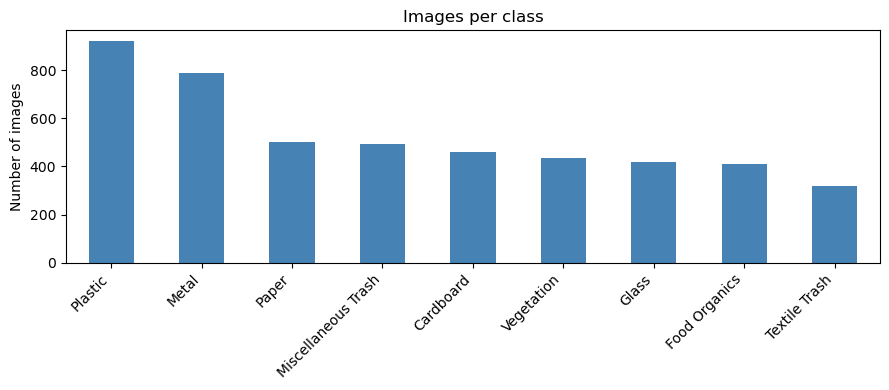

In [3]:
from PIL import Image

# Dataset structure and class distribution 
image_paths = {}
for name in class_names:
    folder = data_dir / name
    image_paths[name] = [p for p in folder.iterdir()
                         if p.suffix.lower() in ('.jpg', '.jpeg', '.png')]

counts = pd.Series({k: len(v) for k, v in image_paths.items()}).sort_values(ascending=False)
print(counts)
print("Total images:", counts.sum())
print("Imbalance ratio (largest / smallest): %.2f" % (counts.max() / counts.min()))

counts.plot(kind='bar', figsize=(9, 4), color='steelblue')
plt.title('Images per class')
plt.ylabel('Number of images')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Findings: Class Distribution

- The dataset has **4,752 images** across **9 classes**.
- It is **imbalanced**. Plastic (921) and Metal (790) are the largest classes, and Textile Trash (318) is the smallest. The imbalance ratio is **2.90**.
- The other six classes are fairly even, with 411 to 500 images each.



In [4]:
# Image characteristics: resolution and colour mode
all_paths = [p for files in image_paths.values() for p in files]
sample = random.sample(all_paths, min(150, len(all_paths)))

rows = []
for p in sample:
    with Image.open(p) as img:
        rows.append({'width': img.width, 'height': img.height, 'mode': img.mode})
size_df = pd.DataFrame(rows)

print(size_df[['width', 'height']].describe())
print("Colour modes:", size_df['mode'].value_counts().to_dict())
print("Unique sizes in sample:", size_df[['width', 'height']].drop_duplicates().shape[0])

       width  height
count  150.0   150.0
mean   524.0   524.0
std      0.0     0.0
min    524.0   524.0
25%    524.0   524.0
50%    524.0   524.0
75%    524.0   524.0
max    524.0   524.0
Colour modes: {'RGB': 150}
Unique sizes in sample: 1


### Findings: Image Characteristics

- In a random sample of 150 images, **every image is 524 x 524 pixels** (only 1 unique size), and all are in **RGB** colour mode.
- The images are square, so resizing to 224 x 224 for the CNN will not stretch or distort them.
- This uniformity is unlike real resident photos, which vary in size, shape and quality. This is a limitation for real-world use.

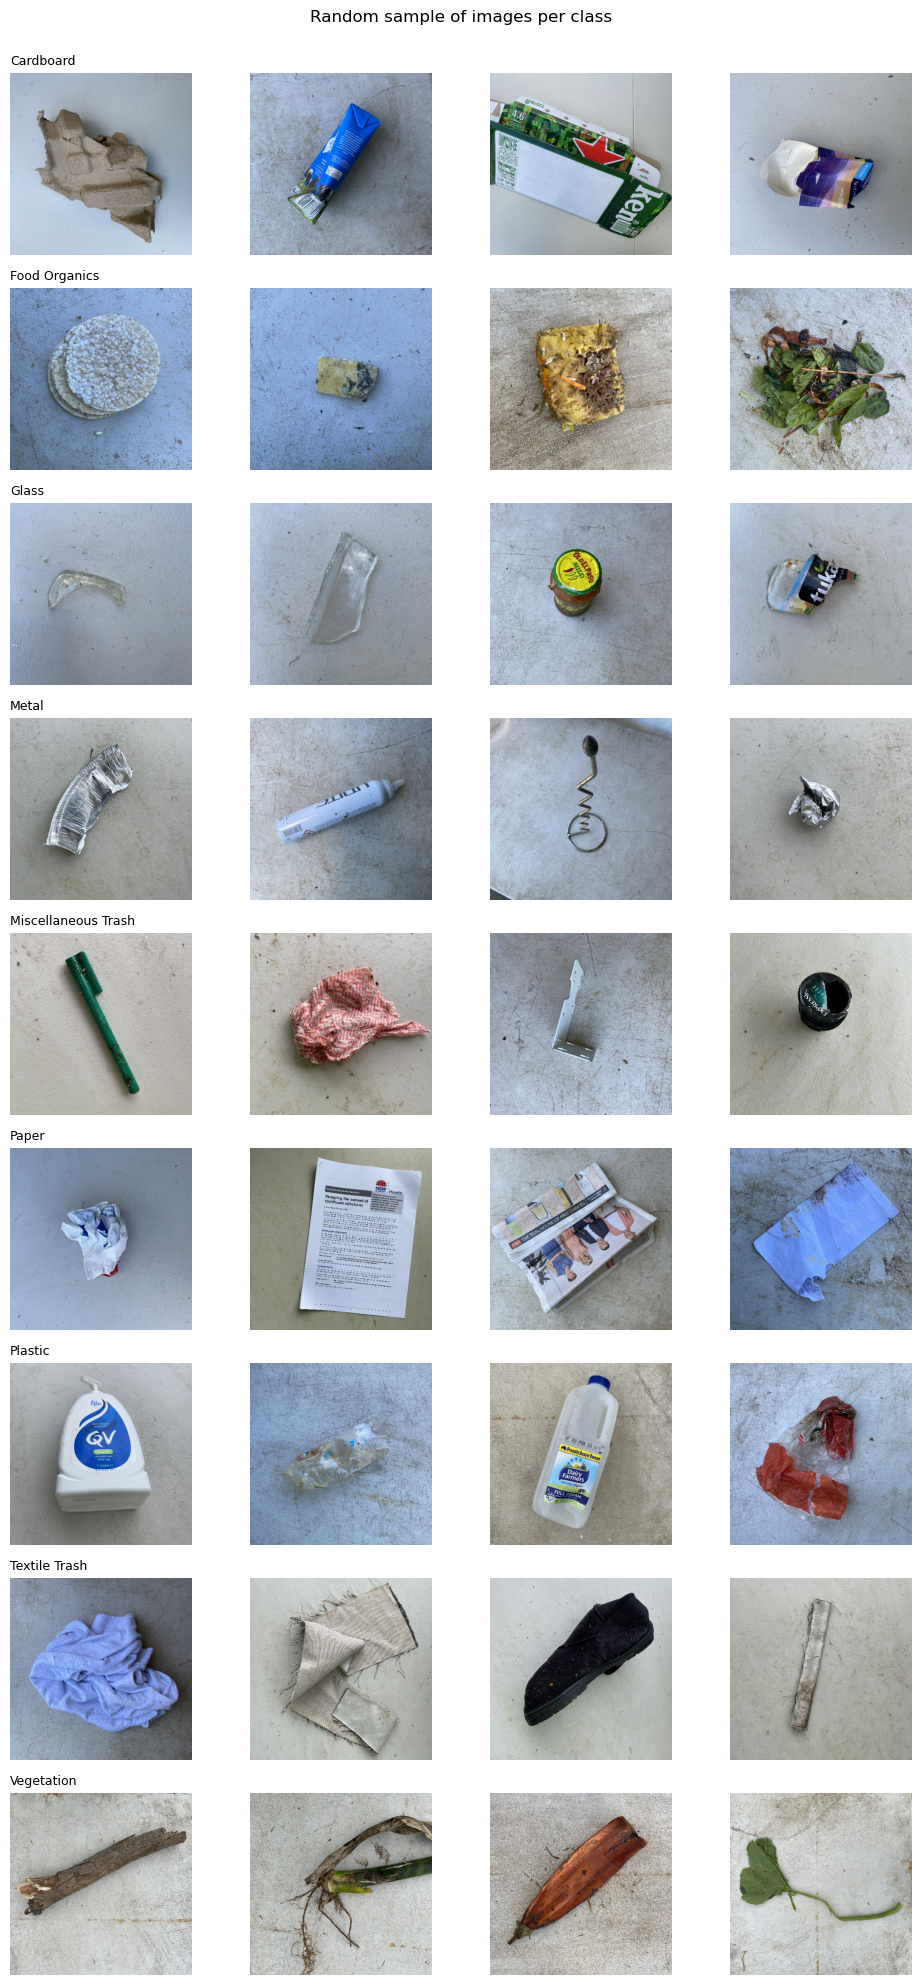

In [5]:
# Visual inspection: quality and background 
n_per_class = 4   # images shown per class

fig, axes = plt.subplots(len(class_names), n_per_class,
                         figsize=(10, 2.2 * len(class_names)))

for i, name in enumerate(class_names):
    picks = random.sample(image_paths[name], n_per_class)   # random images from this class
    for j, p in enumerate(picks):
        with Image.open(p) as img:
            axes[i][j].imshow(img)
        axes[i][j].axis('off')                  # hide the axis ticks
        if j == 0:
            axes[i][j].set_title(name, loc='left', fontsize=9)   # class name on each row

plt.suptitle('Random sample of images per class', y=1.0)
plt.tight_layout()
plt.show()

### Findings: Visual Inspection

- Every photo shows **one item on a plain grey concrete floor**, taken from above in even light. The images are sharp.
- The floor is **stained and dirty in places**, and the item is not always centred, but the background stays consistent across classes.
- Items vary in condition (peeled bananas, crushed cans, broken glass), so there is variety within each class.
- **Classes that may be confused:**
  - Glass vs Metal (shiny items on grey).
  - Paper vs Cardboard.
  - Food Organics vs Vegetation.
  - Miscellaneous Trash vs Textile Trash (the Miscellaneous Trash row includes cloth-like items).
- **Limitation:** resident photos will have cluttered backgrounds, different lighting and angles, and several items in one frame. Accuracy on real photos may be lower than on this dataset.

### 1.2 Explore Text Datasets

#### TODO: Load and explore the waste description text data
##### - Load waste_descriptions.csv
##### - Analyze vocabulary and structure
##### - Understand the distribution of categories



In [6]:
 df = pd.read_csv(csv_path)

In [7]:
df.head()

,description,category,disposal_instruction,common_confusion,material_composition
0,soiled silver tablecloth,Textile Trash,Look for textile recycling programs in your area.,NaN,"Fabric made from natural or synthetic fibers, ..."
1,folded glass bottle leaking,Glass,"Remove caps, lids, and corks before recycling.",NaN,"Silica-based material, may contain additives f..."
2,large Supermarket vegetable waste with food re...,Food Organics,"If no compost available, place in general waste.",NaN,Biodegradable matter derived from plant or ani...
3,intact floral carpet piece,Textile Trash,Look for textile recycling programs in your area.,NaN,"Fabric made from natural or synthetic fibers, ..."
4,empty fun-sized purple apple core,Food Organics,Keep separate from recyclable materials.,Meat and dairy products may be restricted in s...,Biodegradable matter derived from plant or ani...


In [8]:
df.shape

(5000, 5)

In [9]:
df.columns.tolist()

['description',
 'category',
 'disposal_instruction',
 'common_confusion',
 'material_composition']

In [10]:
df.isna().sum()

description                0
category                   0
disposal_instruction       0
common_confusion        2504
material_composition       0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(7)

In [12]:
df['description'].duplicated().sum()

np.int64(61)

In [13]:
df['description'].nunique()

4939

In [14]:
df.describe()

,description,category,disposal_instruction,common_confusion,material_composition
count,5000,5000,5000,2496,5000
unique,4939,9,44,9,9
top,glass tabletop,Vegetation,Rinse container before recycling.,Invasive species may require special disposal....,Plant matter composed primarily of cellulose a...
freq,3,600,239,315,600


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   description           5000 non-null   object
 1   category              5000 non-null   object
 2   disposal_instruction  5000 non-null   object
 3   common_confusion      2496 non-null   object
 4   material_composition  5000 non-null   object
dtypes: object(5)
memory usage: 195.4+ KB


In [16]:
   conflicts = df.groupby('description')['category'].nunique()
   print("Descriptions under more than one category:", (conflicts > 1).sum())

Descriptions under more than one category: 0


In [17]:
   df_clean = df.drop_duplicates(subset='description').reset_index(drop=True)
   print(df.shape, '->', df_clean.shape)

(5000, 5) -> (4939, 5)


### Findings: Text Data

- 5,000 descriptions, 9 categories, no missing values in `description` or `category`.
- 4,939 unique descriptions, so about 61 are duplicates; removed them before splitting to avoid leakage between train and test.
- `material_composition` and `common_confusion` each have only 9 unique values (one per category), and `disposal_instruction` has 44, so they reveal the label.  use only `description` as input.



 category
Vegetation             600
Textile Trash          586
Cardboard              584
Miscellaneous Trash    578
Plastic                569
Glass                  551
Food Organics          518
Metal                  508
Paper                  506
Name: count, dtype: int64


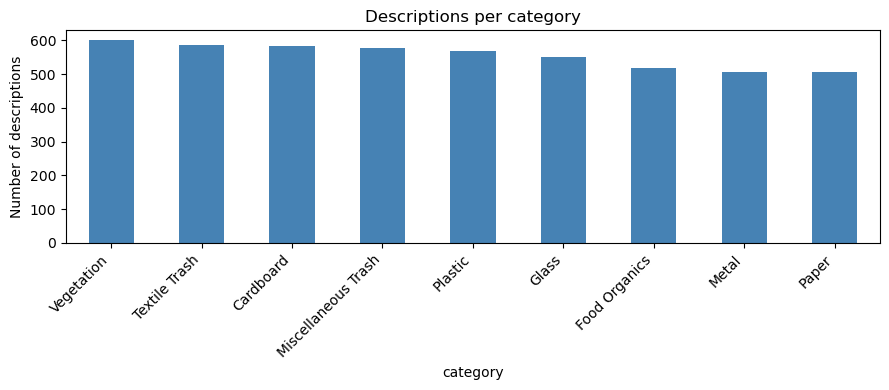

In [18]:
# Category distribution 
cat_counts = df['category'].value_counts()
print("\n", cat_counts)
cat_counts.plot(kind='bar', figsize=(9, 4), color='steelblue')
plt.title('Descriptions per category')
plt.ylabel('Number of descriptions')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Findings: Text Category Distribution

- The 5,000 descriptions are spread across **9 categories** and are **well balanced**: from **506 (Paper)** to **600 (Vegetation)**, a ratio of about 1.19.
- Unlike the image data, there is no strong imbalance here (the images had a ratio of 2.90), so the text classifier does not need class weights or resampling.
- **Accuracy is a reasonable metric** for this data, but  will still report per-class precision and recall, and use a stratified split to keep these proportions in train, validation and test.


Words per description:
count    5000.000000
mean        4.854000
std         1.549956
min         1.000000
25%         4.000000
50%         5.000000
75%         6.000000
max        10.000000
Name: word_count, dtype: float64


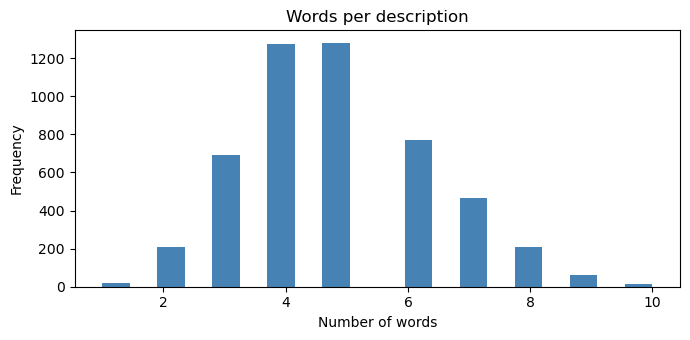

In [19]:
#  Description length 
df['word_count'] = df['description'].str.split().str.len()
print("\nWords per description:")
print(df['word_count'].describe())

df['word_count'].plot(kind='hist', bins=20, figsize=(7, 3.5), color='steelblue')
plt.title('Words per description')
plt.xlabel('Number of words')
plt.tight_layout()
plt.show()

### Findings: Description Length

- Descriptions are **very short**: on average **4.9 words**, with a median of 5. Most have 4 to 6 words, and the range is **1 to 10 words**.
- The distribution is roughly symmetric, with a peak at 4 to 5 words and few very short or long descriptions.
- **Impact on modelling:** there is little context in each description, so a simple model (TF-IDF with logistic regression) should work well, and a sequence length of 10 to 12 tokens is enough for any neural model, so no long padding or truncation is needed.


In [20]:
import re
from collections import Counter

# Vocabulary
tokens = Counter(w for text in df['description'] for w in re.findall(r"[a-z']+", text.lower()))
print("\nVocabulary size:", len(tokens))
print("Most common words:", tokens.most_common(15))


Vocabulary size: 309
Most common words: [('with', 727), ('sized', 534), ('glass', 424), ('empty', 348), ('bottle', 342), ('food', 316), ('paper', 316), ('box', 313), ('residue', 309), ('plastic', 280), ('metal', 270), ('brand', 247), ('dry', 211), ('new', 196), ('soiled', 189)]


### Findings: Vocabulary

- The vocabulary is **small: only 309 unique words** across 5,000 descriptions, which confirms the text is templated and repetitive.
- The most common words are a mix of:
  - **Material words** such as *glass* (424), *paper* (316), *plastic* (280), *metal* (270), *food* (316).
  - **Item words** such as *bottle* (342) and *box* (313).
  - **Condition and size words** such as *with* (727), *sized* (534), *empty* (348), *residue* (309), *dry*, *new* and *soiled*.


###  TODO: Load and explore the waste policy documents
##### - Load waste_policy_documents.csv
##### Understand document organization and language



In [21]:
#Load dataset 
with open('waste_policy_documents.json') as f:
    policies = json.load(f)


In [22]:
# Structure
print("Number of documents:", len(policies))
print("Keys per document:", list(policies[0].keys()))

pol_df = pd.DataFrame(policies)
pol_df['n_categories'] = pol_df['categories_covered'].apply(len)
pol_df['n_words'] = pol_df['document_text'].str.split().str.len()
display(pol_df[['policy_id', 'policy_type', 'categories_covered', 'effective_date', 'n_categories', 'n_words']])

print("\nJurisdictions:", pol_df['jurisdiction'].unique().tolist())
print("Date range:", pol_df['effective_date'].min(), "to", pol_df['effective_date'].max())

Number of documents: 14
Keys per document: ['policy_id', 'policy_type', 'categories_covered', 'effective_date', 'document_text', 'jurisdiction']


,policy_id,policy_type,categories_covered,effective_date,n_categories,n_words
0,1,Textile Trash Recycling Guidelines,[Textile Trash],2023-11-04,1,104
1,2,Glass Recycling Guidelines,[Glass],2023-01-24,1,86
2,3,Food Organics Recycling Guidelines,[Food Organics],2023-05-08,1,98
3,4,Plastic Recycling Guidelines,[Plastic],2023-04-05,1,94
4,5,Vegetation Recycling Guidelines,[Vegetation],2023-12-04,1,94
5,6,Cardboard Recycling Guidelines,[Cardboard],2023-11-24,1,87
6,7,Metal Recycling Guidelines,[Metal],2023-09-03,1,102
7,8,Paper Recycling Guidelines,[Paper],2023-10-14,1,95
8,9,Miscellaneous Trash Recycling Guidelines,[Miscellaneous Trash],2023-01-01,1,97
9,10,Municipal Waste Guidelines,"[Plastic, Miscellaneous Trash, Vegetation]",2023-10-01,3,100



Jurisdictions: ['Metro City']
Date range: 2023-01-01 to 2023-12-15


In [23]:
#  Which documents cover each category? 
coverage = {}
for doc in policies:
    for cat in doc['categories_covered']:
        coverage.setdefault(cat, []).append(doc['policy_id'])
for cat in sorted(coverage):
    print(f"{cat:22s} -> documents {coverage[cat]}")

Cardboard              -> documents [6, 13, 14]
Food Organics          -> documents [3, 12]
Glass                  -> documents [2, 11, 13]
Metal                  -> documents [7, 11, 12, 14]
Miscellaneous Trash    -> documents [9, 10, 11, 12]
Paper                  -> documents [8]
Plastic                -> documents [4, 10, 11]
Textile Trash          -> documents [1, 13, 14]
Vegetation             -> documents [5, 10, 11, 14]



Words per document:
count     14.000000
mean     101.785714
std       15.115853
min       86.000000
25%       94.250000
50%       99.000000
75%      102.000000
max      146.000000
Name: n_words, dtype: float64


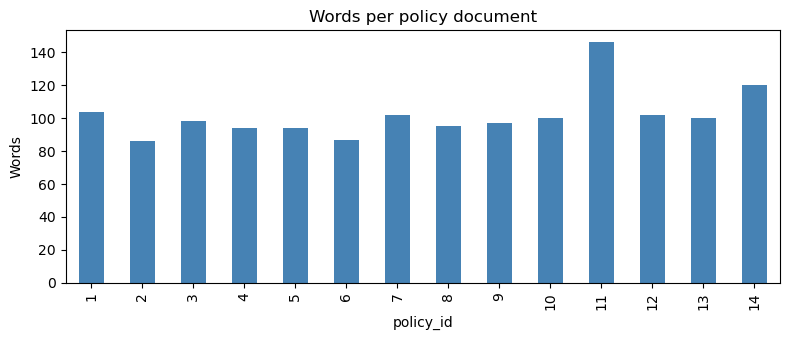

In [24]:
#  Document length 
print("\nWords per document:")
print(pol_df['n_words'].describe())
pol_df.set_index('policy_id')['n_words'].plot(kind='bar', figsize=(8, 3.5), color='steelblue')
plt.title('Words per policy document')
plt.xlabel('policy_id')
plt.ylabel('Words')
plt.tight_layout()
plt.show()

### Findings: Policy Document Length

- There are **14 policy documents**, and they are **short**: about **102 words on average**, ranging from **86 to 146 words**.
- Lengths are fairly uniform. Document 11 (Residential Recycling Rules) is the longest at 146 words, and Documents 2 and 6 are the shortest.


In [25]:
#  Document language and organisation 
# Section headings are lines that end with ':' or are written in capitals.
headings = Counter()
for doc in policies:
    for line in doc['document_text'].split('\n'):
        line = line.strip()
        if line.endswith(':') or (line.isupper() and len(line) > 3):
            headings[line] += 1
print("\nSection headings and how often they appear:")
for h, n in headings.most_common():
    print(f"  {n:2d}  {h}")


Section headings and how often they appear:
   9  Benefits:
   8  Acceptable Items:
   8  Non-Acceptable Items:
   8  Collection Method:
   8  Preparation Instructions:
   5  GENERAL REQUIREMENTS:
   3  MISCELLANEOUS TRASH GUIDELINES:
   3  VEGETATION GUIDELINES:
   3  METAL GUIDELINES:
   2  PLASTIC GUIDELINES:
   2  GLASS GUIDELINES:
   2  CARDBOARD GUIDELINES:
   2  TEXTILE TRASH GUIDELINES:
   1  TEXTILE RECYCLING GUIDELINES
   1  GLASS RECYCLING GUIDELINES
   1  FOOD ORGANICS RECYCLING GUIDELINES
   1  PLASTIC RECYCLING GUIDELINES
   1  VEGETATION RECYCLING GUIDELINES
   1  CARDBOARD RECYCLING GUIDELINES
   1  METAL RECYCLING GUIDELINES
   1  PAPER RECYCLING GUIDELINES
   1  MISCELLANEOUS TRASH GUIDELINES
   1  Items That Cannot Be Recycled:
   1  Special Handling Items:
   1  Waste Reduction Tips:
   1  MUNICIPAL WASTE GUIDELINES
   1  RESIDENTIAL RECYCLING RULES
   1  COMMERCIAL RECYCLING STANDARDS
   1  FOOD ORGANICS GUIDELINES:
   1  MULTI-UNIT BUILDING GUIDELINES
   1  COMMU

### Findings: Policy Document Organisation

- The documents follow **two layouts**:
  - **Single-category documents (IDs 1-8)** have the same five sections: *Acceptable Items, Non-Acceptable Items, Collection Method, Preparation Instructions* and *Benefits*. Each begins with a title line such as "GLASS RECYCLING GUIDELINES".
  - **Multi-category documents (IDs 10-14)** start with *GENERAL REQUIREMENTS*, followed by short sections per category (for example "METAL GUIDELINES:"). They list items but have **no Non-Acceptable, Collection or Preparation sections**.
- **Miscellaneous Trash (ID 9)** has its own structure: *Items That Cannot Be Recycled, Special Handling Items, Waste Reduction Tips* and *Benefits*.
- The language is short and instruction-like (bulleted lists, imperative verbs), and the same bullet lists are repeated across documents.


In [26]:
#  Read two documents 
print("\n--- Single-category document (id 2) ---")
print(next(d for d in policies if d['policy_id'] == 2)['document_text'])
print("\n--- Multi-category document (id 11) ---")
print(next(d for d in policies if d['policy_id'] == 11)['document_text'])


--- Single-category document (id 2) ---
GLASS RECYCLING GUIDELINES

Acceptable Items:
- Glass bottles (all colors)
- Glass jars
- Glass food containers
- Glass beverage containers

Non-Acceptable Items:
- Window glass or mirrors
- Drinking glasses
- Ceramics or pottery
- Light bulbs
- Pyrex or heat-resistant glass

Collection Method:
Place in dedicated glass recycling bins. Some areas require color sorting.

Preparation Instructions:
- Rinse containers
- Remove caps and lids (recycle separately)
- Labels can remain

Benefits:
Glass is 100% recyclable and can be recycled endlessly without loss of quality.

--- Multi-category document (id 11) ---
RESIDENTIAL RECYCLING RULES

GENERAL REQUIREMENTS:
- Place recyclables in appropriate bins
- Ensure materials are clean and properly sorted
- Follow collection schedules
- Keep hazardous materials separate


PLASTIC GUIDELINES:
- PET bottles and containers (code #1)
- HDPE containers (code #2)
- PP containers (code #5)
- Clean plastic packaging

### Findings: Single-Category vs Multi-Category Documents

- **Document 2 (Glass)** is complete and clearly structured. It separates *Acceptable* from *Non-Acceptable* items, and adds collection and preparation steps (rinse containers, remove caps and lids, labels can stay).
- **Document 11 (Residential Recycling Rules)** is a summary. It starts with general rules, then gives one flat list per material, with **no acceptable/non-acceptable split and no preparation steps**.
- **Conflict found:** "Window glass or mirrors" is **non-acceptable** in Document 2, but it appears in Document 11's Glass list with no warning, so it reads as accepted. The same pattern appears for "Plastic bags and film" (non-acceptable in Document 4, but listed in the plastic guidelines of Documents 10 and 11).
- **Decision for RAG:** retrieve from the **single-category document first**, because it is complete and states exclusions. Use the multi-category documents only for general requirements, or when no single-category document exists for a topic.


In [27]:
#  Do documents contradict each other? 
def docs_containing(phrase):
    return [d['policy_id'] for d in policies if phrase.lower() in d['document_text'].lower()]

print("\n'Window glass or mirrors' appears in documents:", docs_containing("window glass or mirrors"))
print("'Plastic bags and film' appears in documents:", docs_containing("plastic bags and film"))


'Window glass or mirrors' appears in documents: [2, 11, 13]
'Plastic bags and film' appears in documents: [4, 10, 11]


### Findings: Contradictions Between Documents

- **Window glass or mirrors** appears in documents **2, 11 and 13**. Document 2 (Glass) lists it as **non-acceptable**, while documents 11 and 13 list it in their Glass guidelines with no exclusion.
- **Plastic bags and film** appears in documents **4, 10 and 11**. Document 4 (Plastic) lists it as **non-acceptable**, while documents 10 and 11 include it in their plastic lists.
- So the **multi-category documents can give the opposite advice** from the single-category ones, and a retriever that picks the wrong one could tell a resident to put window glass or plastic bags in the recycling bin.
- **My rule:** the single-category documents take priority, because they state exclusions explicitly. The multi-category documents will be used only for general requirements.


### Summary: Policy Documents

- There are **14 short policy documents** (about 102 words each, from 86 to 146) from one jurisdiction, **Metro City**.
- **Documents 1-8** each cover one material and follow the same layout: Acceptable Items, Non-Acceptable Items, Collection Method, Preparation Instructions and Benefits. **Document 9** covers Miscellaneous Trash with its own sections.
- **Documents 10-14** cover several categories at once. They are shorter summaries with flat item lists and no exclusions or preparation steps.
- The language is short and instruction-like, with bulleted lists and repeated wording across documents.
- **Problem found:** the documents contradict each other. "Window glass or mirrors" is non-acceptable in the Glass document (2) but is listed without an exclusion in documents 11 and 13. "Plastic bags and film" is non-acceptable in the Plastic document (4) but is listed in documents 10 and 11.
- **Decision:** for RAG, I will use the single-category documents first, because they state exclusions, and use the multi-category ones only for general requirements.

### 1.3 Create Data Pipelines

In [28]:
# Run this code to setup the images properly into train, validation, and test sets
# Set your data directory path - update this with your actual path
import pathlib
data_dir = pathlib.Path(r"C:\Users\BRIDGIT\Downloads\realwaste\realwaste-main\RealWaste\RealWaste")


# Parameters
BATCH_SIZE = 32
IMG_HEIGHT = 224
IMG_WIDTH = 224

# Calculate the total number of classes automatically from the directory structure
num_classes = len([item for item in data_dir.glob('*') if item.is_dir()])
print(f"Number of classes: {num_classes}")

# List all class folders
class_names = sorted([item.name for item in data_dir.glob('*') if item.is_dir()])
print(f"Class names: {class_names}")

# Count all images
image_count = len(list(data_dir.glob('*/*.jpg'))) + len(list(data_dir.glob('*/*.png')))
print(f"Total images found: {image_count}")

# Create a dataset using tf.keras.utils.image_dataset_from_directory
# This will automatically split the data into training and validation sets
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,  # 20% for validation
    subset="training",
    seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='categorical',  # For one-hot encoded labels
    shuffle=True
)

validation_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,  # 20% for validation
    subset="validation",
    seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='categorical',  # For one-hot encoded labels
    shuffle=True
)

# Create a separate test dataset by taking part of the validation set
# First, let's get the number of batches in the validation set
val_batches = tf.data.experimental.cardinality(validation_ds)
test_dataset = validation_ds.take(val_batches // 2)
validation_ds = validation_ds.skip(val_batches // 2)

print(f"Number of training batches: {tf.data.experimental.cardinality(train_ds)}")
print(f"Number of validation batches: {tf.data.experimental.cardinality(validation_ds)}")
print(f"Number of test batches: {tf.data.experimental.cardinality(test_dataset)}")

# Configure dataset for performance
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
validation_ds = validation_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

Number of classes: 9
Class names: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
Total images found: 4752
Found 4752 files belonging to 9 classes.
Using 3802 files for training.
Found 4752 files belonging to 9 classes.
Using 950 files for validation.
Number of training batches: 119
Number of validation batches: 15
Number of test batches: 15


In [29]:
# Class proportions per split (image data)
def class_counts(ds):
    y = np.concatenate([np.argmax(l.numpy(), axis=1) for _, l in ds])
    return pd.Series(np.bincount(y, minlength=len(class_names)), index=class_names)

split_counts = pd.DataFrame({'train': class_counts(train_ds),
                             'validation': class_counts(validation_ds),
                             'test': class_counts(test_dataset)})
split_pct = (split_counts / split_counts.sum() * 100).round(1)          # class share within each split
split_pct['all data'] = (split_counts.sum(axis=1) / split_counts.values.sum() * 100).round(1)

print("Images per split:", split_counts.sum().to_dict())
display(split_counts)
display(split_pct)
gap = split_pct[['train', 'validation', 'test']].sub(split_pct['all data'], axis=0).abs().max().max()
print("Largest gap between a split and the full data: %.1f percentage points" % gap)

Images per split: {'train': 3802, 'validation': 470, 'test': 480}


,train,validation,test
Cardboard,387,31,37
Food Organics,327,47,36
Glass,342,39,37
Metal,617,81,93
Miscellaneous Trash,403,36,52
Paper,381,59,66
Plastic,742,97,81
Textile Trash,243,36,43
Vegetation,360,44,35


,train,validation,test,all data
Cardboard,10.2,6.6,7.7,9.6
Food Organics,8.6,10.0,7.5,8.6
Glass,9.0,8.3,7.7,8.8
Metal,16.2,17.2,19.4,16.6
Miscellaneous Trash,10.6,7.7,10.8,10.3
Paper,10.0,12.6,13.8,10.6
Plastic,19.5,20.6,16.9,19.4
Textile Trash,6.4,7.7,9.0,6.8
Vegetation,9.5,9.4,7.3,9.2


Largest gap between a split and the full data: 3.2 percentage points


### Image Split

- The image split is **random*: 80% train (3,802 images), and the other 20% was split
  in half into validation (470) and test (480), using `validation_split=0.2` with seed 42.
- The table compares each class's share in every split with the full data. The splits keep a
  similar class mix, with a **largest gap of 3.2 percentage points** (Paper in the test set:
  13.8% vs 10.6% overall). The next largest is Cardboard in validation (6.6% vs 9.6%).
- Because the split is not stratified, some classes are over- or under-represented in the
  small validation and test sets. Textile Trash, for example, is 6.4% of train but 9.0% of test.
  This means per-class test scores for small classes are somewhat noisy.
- Class imbalance is handled in training with class weights computed on the training labels only.
 

# TODO: Create a text preprocessing pipeline
##### - Tokenization
##### - Text cleaning
##### - Split data into train and test
##### - Create embeddings/features



In [30]:

#  Text cleaning 
def clean_text(text):
    """Lowercase, remove punctuation/digits, collapse extra spaces."""
    text = str(text).lower()
    text = re.sub(r"[^a-z\s]", " ", text)   # keep letters only
    text = re.sub(r"\s+", " ", text).strip()
    return text

df_clean['clean_text'] = df_clean['description'].apply(clean_text)


In [31]:
# Tokenization 
def tokenize(text):
    return text.split()

df_clean['tokens'] = df_clean['clean_text'].apply(tokenize)


In [32]:
# Show before / after
for i in range(5):
    print(df_clean.loc[i, 'description'], '->', df_clean.loc[i, 'tokens'])

soiled silver tablecloth -> ['soiled', 'silver', 'tablecloth']
folded glass bottle leaking -> ['folded', 'glass', 'bottle', 'leaking']
large Supermarket vegetable waste with food residue -> ['large', 'supermarket', 'vegetable', 'waste', 'with', 'food', 'residue']
intact floral carpet piece -> ['intact', 'floral', 'carpet', 'piece']
empty fun-sized purple apple core -> ['empty', 'fun', 'sized', 'purple', 'apple', 'core']


In [33]:
from sklearn.preprocessing import LabelEncoder

# Encode labels
le = LabelEncoder()
y = le.fit_transform(df_clean['category'])
print("\nClasses:", list(le.classes_))


Classes: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']


In [34]:
#  Stratified train / validation / test split (70 / 15 / 15) 
X = df_clean['clean_text']

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

print("\nTrain:", len(X_train), "| Validation:", len(X_val), "| Test:", len(X_test))


Train: 3457 | Validation: 741 | Test: 741


In [35]:
# Check that class proportions are preserved in each split
split_check = pd.DataFrame({
    'train': pd.Series(y_train).value_counts(normalize=True).sort_index(),
    'val':   pd.Series(y_val).value_counts(normalize=True).sort_index(),
    'test':  pd.Series(y_test).value_counts(normalize=True).sort_index(),
}).round(3)
split_check.index = le.classes_
print("\nClass proportions per split:\n", split_check)


Class proportions per split:
                      train    val   test
Cardboard            0.118  0.117  0.117
Food Organics        0.104  0.104  0.103
Glass                0.110  0.109  0.109
Metal                0.102  0.103  0.101
Miscellaneous Trash  0.117  0.116  0.117
Paper                0.100  0.100  0.101
Plastic              0.112  0.112  0.113
Textile Trash        0.118  0.119  0.119
Vegetation           0.119  0.120  0.119


In [36]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Features: TF-IDF (fit on TRAIN only)
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
X_train_tfidf = tfidf.fit_transform(X_train)    # learn vocabulary from train only
X_val_tfidf   = tfidf.transform(X_val)          # only apply to val and test
X_test_tfidf  = tfidf.transform(X_test)

print("TF-IDF matrix shapes:", X_train_tfidf.shape, X_val_tfidf.shape, X_test_tfidf.shape)
print("Number of features:", len(tfidf.get_feature_names_out()))

# Leakage check: identical cleaned text in train and test?
overlap = set(X_train) & set(X_test)
print("Cleaned texts shared by train and test:", len(overlap))

TF-IDF matrix shapes: (3457, 2380) (741, 2380) (741, 2380)
Number of features: 2380
Cleaned texts shared by train and test: 0


### Findings: TF-IDF Features

- The text was converted into **TF-IDF features** using single words and word pairs (1-2 grams), ignoring terms that appear in fewer than 2 descriptions.
- The result is **2,380 features**. The matrices are **3,457 x 2,380 (train)**, **741 x 2,380 (validation)** and **741 x 2,380 (test)**: the same number of features in every set, with 70% / 15% / 15% of the 4,939 descriptions.
- The vectorizer was **fitted on the training set only**, then applied to validation and test, so no information leaks from them into training.
- **Leakage check:** **0 cleaned descriptions** are shared between train and test, so the test score will not be inflated by repeated text.
- The feature count is much larger than the 309-word vocabulary because word pairs (for example "glass bottle") are included.

### TODO: Prepare documents for RAG
##### - Document preprocessing
##### - Create embeddings for retrieval



In [37]:
# Document preprocessing: split each document into section chunks 
CATEGORIES = ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash',
              'Paper', 'Plastic', 'Textile Trash', 'Vegetation']

def heading_to_category(heading):
    """'METAL GUIDELINES:' -> 'Metal'; returns None if no category is named."""
    h = heading.lower()
    for cat in CATEGORIES:
        if cat.lower() in h:
            return cat
    return None

def chunk_document(doc):
    single = len(doc['categories_covered']) == 1
    lines = [l.strip() for l in doc['document_text'].split('\n')]
    chunks, section, body = [], 'Overview', []

    def flush():
        text = '; '.join(body).strip()
        if text:
            if single:
                cat = doc['categories_covered'][0]
            else:
                cat = heading_to_category(section) or 'General'
            chunks.append({
                'policy_id': doc['policy_id'],
                'policy_type': doc['policy_type'],
                'doc_kind': 'single' if single else 'multi',
                'category': cat,
                'section': section.rstrip(':'),
                'effective_date': doc['effective_date'],
                'text': text,
            })

    for line in lines:
        if not line:
            continue
        is_heading = line.endswith(':') and not line.startswith('-')
        is_title = line.isupper() and not line.startswith('-')
        if is_heading or is_title:
            flush()
            body = []
            section = line if is_heading else 'Overview'
        else:
            body.append(line.lstrip('- ').strip())
    flush()
    return chunks

all_chunks = [c for doc in policies for c in chunk_document(doc)]
chunks_df = pd.DataFrame(all_chunks)

# Text that will be embedded: add category + section so the meaning is clear
chunks_df['embed_text'] = chunks_df['category'] + ' - ' + chunks_df['section'] + ': ' + chunks_df['text']

# Drop empty "Overview" chunks that are just titles
chunks_df = chunks_df[chunks_df['text'].str.len() > 0].reset_index(drop=True)

print("Number of chunks:", len(chunks_df))
print(chunks_df.groupby('doc_kind').size())
print(chunks_df[['policy_id', 'doc_kind', 'category', 'section']].head(12))
print("\nExample chunk:\n", chunks_df.loc[1, 'embed_text'])

Number of chunks: 67
doc_kind
multi     23
single    44
dtype: int64
    policy_id doc_kind       category                   section
0           1   single  Textile Trash          Acceptable Items
1           1   single  Textile Trash      Non-Acceptable Items
2           1   single  Textile Trash         Collection Method
3           1   single  Textile Trash  Preparation Instructions
4           1   single  Textile Trash                  Benefits
5           2   single          Glass          Acceptable Items
6           2   single          Glass      Non-Acceptable Items
7           2   single          Glass         Collection Method
8           2   single          Glass  Preparation Instructions
9           2   single          Glass                  Benefits
10          3   single  Food Organics          Acceptable Items
11          3   single  Food Organics      Non-Acceptable Items

Example chunk:
 Textile Trash - Non-Acceptable Items: Wet or moldy textiles; Heavily soiled items;

### Findings: RAG Document Preparation

- The 14 policy documents were split into **67 chunks**, one per section heading: **44 from single-category documents** and **23 from multi-category documents**.
- Each chunk keeps **metadata**: policy id, document type (single or multi), category, section name and effective date. This lets retrieval filter by the predicted category and lets me trace each answer to its source.
- For multi-category documents, the category of each chunk is read from its heading (for example "METAL GUIDELINES"), so those chunks are also searchable by category.
- **The bullets of each section are joined with semicolons**, not plain spaces. For example: *"Textile Trash - Non-Acceptable Items: Wet or moldy textiles; Heavily soiled items; Carpets and rugs; Footwear; Items with significant non-textile parts"*. Keeping the items separate lets me later compare them one by one (for example to remove an excluded item from a summary document), and it makes the generated instructions easier to read.
- Sections such as **Non-Acceptable Items** are separate chunks, so exclusions can be retrieved directly and are not buried inside a long document.

In [38]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer

#  Embeddings: TF-IDF vectors of each chunk 
chunk_vectorizer = TfidfVectorizer(ngram_range=(1, 2), stop_words='english', sublinear_tf=True)
chunk_embeddings = chunk_vectorizer.fit_transform(chunks_df['embed_text'])   # rows are L2-normalised
print("Embedding matrix:", chunk_embeddings.shape)


Embedding matrix: (67, 827)


In [39]:
#  Retriever: cosine similarity (dot product of normalised vectors) 
def retrieve(query, category=None, k=3, prefer_single=True):
    q = chunk_vectorizer.transform([query])
    scores = (chunk_embeddings @ q.T).toarray().ravel()

    if category is not None:                      # only search chunks for the predicted category
        scores = np.where((chunks_df['category'] == category).values, scores, -1)

    if prefer_single:                             # small boost for the complete single-category documents
        scores = scores + 0.05 * (chunks_df['doc_kind'] == 'single').values

    top = np.argsort(scores)[::-1][:k]
    out = chunks_df.iloc[top][['policy_id', 'doc_kind', 'category', 'section', 'text']].copy()
    out['score'] = scores[top].round(3)
    return out

In [40]:
# Sanity checks 
for q, cat in [("Can I recycle window glass?", None),
               ("How do I prepare plastic bottles?", "Plastic"),
               ("Where do I take batteries?", None),
               ("What items are not accepted for textile recycling?", "Textile Trash")]:
    print("\nQUERY:", q)
    display(retrieve(q, category=cat, k=3))


QUERY: Can I recycle window glass?


,policy_id,doc_kind,category,section,text,score
51,11,multi,Glass,GLASS GUIDELINES,Glass bottles (all colors); Glass jars; Glass ...,0.370
60,13,multi,Glass,GLASS GUIDELINES,Glass bottles (all colors); Glass jars; Glass ...,0.370
6,2,single,Glass,Non-Acceptable Items,Window glass or mirrors; Drinking glasses; Cer...,0.335



QUERY: How do I prepare plastic bottles?


,policy_id,doc_kind,category,section,text,score
15,4,single,Plastic,Acceptable Items,PET bottles and containers (code #1); HDPE con...,0.298
45,10,multi,Plastic,PLASTIC GUIDELINES,PET bottles and containers (code #1); HDPE con...,0.272
49,11,multi,Plastic,PLASTIC GUIDELINES,PET bottles and containers (code #1); HDPE con...,0.272



QUERY: Where do I take batteries?


,policy_id,doc_kind,category,section,text,score
41,9,single,Miscellaneous Trash,Special Handling Items,Batteries (take to dedicated collection points...,0.20
33,7,single,Metal,Preparation Instructions,Rinse containers to remove food residue; Crush...,0.05
18,4,single,Plastic,Preparation Instructions,Rinse containers; Remove lids and caps (recycl...,0.05



QUERY: What items are not accepted for textile recycling?


,policy_id,doc_kind,category,section,text,score
4,1,single,Textile Trash,Benefits,Textile recycling conserves resources and redu...,0.366
2,1,single,Textile Trash,Collection Method,Place items in dedicated textile recycling bin...,0.357
3,1,single,Textile Trash,Preparation Instructions,Ensure all items are clean and dry; Remove non...,0.201


### Findings: Retrieval Sanity Checks (baseline retriever)

- I tested the baseline retriever (TF-IDF with a small boost for single-category documents) with 4 queries. Results are **mixed**, and the rankings are the same as before the chunk text was separated with semicolons, because TF-IDF ignores punctuation.
- **Batteries: correct.** The top result is the *Special Handling Items* chunk of the Miscellaneous Trash policy (score 0.20).
- **Window glass: partly correct.** The right chunk (Glass *Non-Acceptable Items*, policy 2) is in the top 3, but it ranks **third**, behind two multi-category chunks (policies 11 and 13). Those chunks list "Window glass or mirrors" with no exclusion, so a resident could be told it is recyclable. The single-category boost (0.05) is too small to fix this.
- **Plastic bottles: wrong section.** The top result is *Acceptable Items*, not *Preparation Instructions*. The multi-category plastic chunks also still contain "Plastic bags and film".
- **Textile "not accepted": wrong section.** The *Non-Acceptable Items* chunk is not in the top 3. The *Benefits* chunk ranks first because it contains the words "textile recycling".
- **Cause:** TF-IDF matches shared words only, so "not accepted" does not match "Non-Acceptable", and "prepare" does not match "Preparation".


### Limitations and Biases of the Datasets

**Image data (RealWaste)**
- **Controlled setting:** every photo shows one item on a plain grey concrete floor, taken from above in even light, and all images are the same size (524 x 524). Resident photos will have cluttered backgrounds, different lighting and angles, and several items in one frame, so real-world accuracy is likely to be lower than the test scores.
- **Class imbalance:** Plastic (921) and Metal (790) are much larger than Textile Trash (318), a ratio of 2.90. I handled this with balanced class weights and per-class metrics.
- **Mixed and ambiguous items:** Miscellaneous Trash combines many different objects, and some items contain several materials (for example a glass jar with a metal lid), so some labels are ambiguous.
- **Class mismatch with the brief:** the assignment describes 8 classes with three glass colours, but the dataset has **9 classes** with a single Glass class. I used the 9 classes found in the folders.
- **Split:** the image split (80% train, 10% validation, 10% test, seed 42) is random and not stratified, so class shares differ slightly between sets.

**Text data (waste_descriptions.csv)**
- **Synthetic and templated:** descriptions average about 5 words, use a vocabulary of only 309 words, and often name the material directly ("glass bottle"). Models score close to 100%, which overstates performance on real resident wording (typos, slang, longer sentences).
- **Duplicates:** 61 duplicate descriptions (5,000 rows, 4,939 unique) were removed before splitting to avoid leakage. No description appears under two categories.
- **Label leakage:** `disposal_instruction`, `common_confusion` and `material_composition` have between 9 and 44 unique values and almost give the category away, so only `description` is used as the input.
- **Missing values:** `common_confusion` is empty in about half the rows. It is not used as a feature.

**Policy documents (waste_policy_documents.json)**
- **Small and fictional:** 14 short documents (about 100 words each) for one jurisdiction (Metro City). Generated instructions can only be checked for consistency with these documents, not for real-world correctness.
- **Contradictions:** the multi-category summaries list items that the single-category policies exclude ("window glass or mirrors" and "plastic bags and film"). I resolved this by trusting the single-category documents and removing 4 conflicting items.
- **Uneven structure:** single-category documents have five sections, while multi-category ones are flat lists without exclusions or preparation steps. Miscellaneous Trash has its own layout.
- **File format mismatch:** the brief refers to the policy file as both `.csv` and `.json`. The actual file is JSON.

**Impact on the project:** the models are tested on clean, controlled, synthetic data, so the reported scores are an upper bound for real use. The stress tests, the confidence threshold and the edge-case tests in later sections show where the system is weakest.

## Part 2: Waste Material Classification with CNN

In this section, you will build a CNN model to classify waste materials from images.

### 2.1 Preprocess Images

### TODO: Implement image preprocessing
###### Apply the preprocessing pipeline created earlier



In [41]:

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.utils.class_weight import compute_class_weight


data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),   # items can lie in any orientation
    layers.RandomRotation(0.15),                    # small rotations
    layers.RandomZoom(0.15),                        # item closer or further away
    layers.RandomContrast(0.2),                     # lighting differences
], name="data_augmentation")




In [42]:
#  Normalization for the pretrained base model 
# MobileNetV2 expects pixel values scaled to [-1, 1]
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

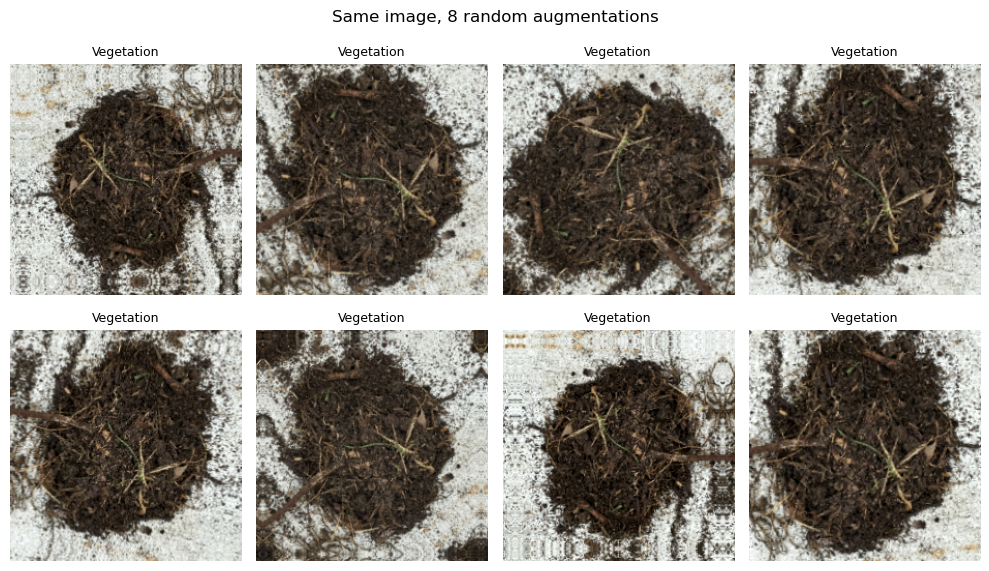

In [43]:
# Look at the augmentation on a few training images 
for images, labels in train_ds.take(1):
    plt.figure(figsize=(10, 6))
    img = images[0]
    for i in range(8):
        ax = plt.subplot(2, 4, i + 1)
        aug = data_augmentation(tf.expand_dims(img, 0), training=True)
        plt.imshow(aug[0].numpy().astype("uint8"))
        plt.title(class_names[int(np.argmax(labels[0]))], fontsize=9)
        plt.axis("off")
    plt.suptitle("Same image, 8 random augmentations")
    plt.tight_layout()
    plt.show()


### Augmentation Check

- The figure shows **one Vegetation image changed 8 different ways** by the augmentation layers (random flips, rotation, zoom and contrast).
- Each version is **flipped, turned or zoomed differently**, and the contrast varies slightly. The pile of vegetation is still clearly recognisable in all 8.
- The edges show **reflected borders** (mirror-like patterns at the corners) where rotation and zoom filled the empty space. This is expected and harmless at this strength.
- **Conclusion:** the augmentation creates useful variety without destroying the content, so I keep these settings. If the training accuracy stays much higher than the validation accuracy, I will increase the strength.

In [44]:
# Class weights to handle the imbalance (computed on TRAINING labels only) 
train_labels = np.concatenate([np.argmax(y.numpy(), axis=1) for _, y in train_ds])

weights = compute_class_weight(class_weight='balanced',
                               classes=np.arange(len(class_names)),
                               y=train_labels)
class_weight_dict = {i: w for i, w in enumerate(weights)}

for i, name in enumerate(class_names):
    print(f"{name:22s} images: {np.sum(train_labels == i):4d}   weight: {class_weight_dict[i]:.2f}")

Cardboard              images:  387   weight: 1.09
Food Organics          images:  327   weight: 1.29
Glass                  images:  342   weight: 1.24
Metal                  images:  617   weight: 0.68
Miscellaneous Trash    images:  403   weight: 1.05
Paper                  images:  381   weight: 1.11
Plastic                images:  742   weight: 0.57
Textile Trash          images:  243   weight: 1.74
Vegetation             images:  360   weight: 1.17


### Class Weights

- The training set has **3,802 images**, and the classes are unequal: **Plastic (742)** and **Metal (617)** are the largest, and **Textile Trash (243)** is the smallest.
- I computed **balanced class weights** from the training labels only. They are **lower than 1 for the large classes** (Plastic 0.57, Metal 0.68) and **higher than 1 for the small ones**, with the highest for **Textile Trash (1.74)**, then Food Organics (1.29) and Glass (1.24).
- The remaining classes are close to 1 (Cardboard 1.09, Miscellaneous Trash 1.05, Paper 1.11, Vegetation 1.17).
- These weights go into `model.fit` through `class_weight`, so a mistake on Textile Trash counts about three times as much as a mistake on Plastic (1.74 / 0.57 = 3.05). This stops the model from favouring the big classes just because they have more images.

### 2.2 Implement CNN Model with Transfer Learning

### TODO: Select an appropriate base model and implement transfer learning
##### - Choose from MobileNet, EfficientNet, etc.
##### - Add custom classification layers for the 9 waste categories
##### - Configure loss function and metrics



In [45]:
IMG_SIZE = (224, 224)
NUM_CLASSES = len(class_names)          # 9

#  Base model: MobileNetV2 pretrained on ImageNet 
base_model = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,),
    include_top=False,                  # remove the original 1000-class head
    weights='imagenet')
base_model.trainable = False            # freeze: keep the pretrained features unchanged


In [46]:
# Full model: augmentation -> normalisation -> base -> new head 
inputs = keras.Input(shape=IMG_SIZE + (3,))
x = data_augmentation(inputs)           # only active during training
x = preprocess_input(x)                 # scale pixels to [-1, 1]
x = base_model(x, training=False)       # keep BatchNorm layers in inference mode
x = layers.GlobalAveragePooling2D()(x)  # 7x7x1280 feature map -> 1280 numbers
x = layers.Dropout(0.3)(x)              # regularisation
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)   # one probability per class

model = keras.Model(inputs, outputs, name="waste_cnn")

In [48]:
#  Loss and metrics 
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',    # labels are one-hot (label_mode='categorical')
    metrics=['accuracy'])

model.summary()
print("Trainable weights:", sum(tf.size(w).numpy() for w in model.trainable_weights))
print("Frozen weights:   ", sum(tf.size(w).numpy() for w in model.non_trainable_weights))

Model: "waste_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ data_augmentation (Sequential)       │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ true_divide (TrueDivide)             │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ subtract (Subtract)                  │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         163,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 9)                   │           1,161 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,423,113 (9.24 MB)

 Trainable params: 165,129 (645.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Trainable weights: 165129
Frozen weights:    2257984


### 2.3 Train and Evaluate the Model

# TODO: Train the CNN model
##### - Use appropriate batch size and epochs
##### - Implement regularization to prevent overfitting
##### - Monitor training and validation metrics



In [49]:
EPOCHS = 6            # upper limit; early stopping can end sooner
BATCH_SIZE = 32       # already set in the data pipeline


In [50]:
# Callbacks (regularisation and monitoring) 
callbacks = [
    # stop when validation loss stops improving, and go back to the best weights
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=4,
                                  restore_best_weights=True, verbose=1),
    # halve the learning rate when validation loss is stuck
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                      patience=2, min_lr=1e-6, verbose=1),
    # keep the best model on disk
    keras.callbacks.ModelCheckpoint('best_waste_cnn.keras', monitor='val_accuracy',
                                    save_best_only=True, verbose=0),
]

In [51]:
#  Train the new head 
history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=EPOCHS,
    class_weight=class_weight_dict,     # rare classes count more
    callbacks=callbacks)

C:\Users\BRIDGIT\anaconda3\AnacondA\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/6
119/119 ━━━━━━━━━━━━━━━━━━━━ 173s 1s/step - accuracy: 0.4892 - loss: 1.4004 - val_accuracy: 0.6787 - val_loss: 0.8636 - learning_rate: 0.0010
Epoch 2/6
119/119 ━━━━━━━━━━━━━━━━━━━━ 126s 1s/step - accuracy: 0.6612 - loss: 0.9300 - val_accuracy: 0.7170 - val_loss: 0.7578 - learning_rate: 0.0010
Epoch 3/6
119/119 ━━━━━━━━━━━━━━━━━━━━ 124s 1s/step - accuracy: 0.6962 - loss: 0.7931 - val_accuracy: 0.7255 - val_loss: 0.7178 - learning_rate: 0.0010
Epoch 4/6
119/119 ━━━━━━━━━━━━━━━━━━━━ 124s 1s/step - accuracy: 0.7299 - loss: 0.7193 - val_accuracy: 0.7404 - val_loss: 0.6944 - learning_rate: 0.0010
Epoch 5/6
119/119 ━━━━━━━━━━━━━━━━━━━━ 125s 1s/step - accuracy: 0.7383 - loss: 0.6806 - val_accuracy: 0.7830 - val_loss: 0.6301 - learning_rate: 0.0010
Epoch 6/6
119/119 ━━━━━━━━━━━━━━━━━━━━ 134s 1s/step - accuracy: 0.7538 - loss: 0.6476 - val_accuracy: 0.7851 - val_loss: 0.6075 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 6.


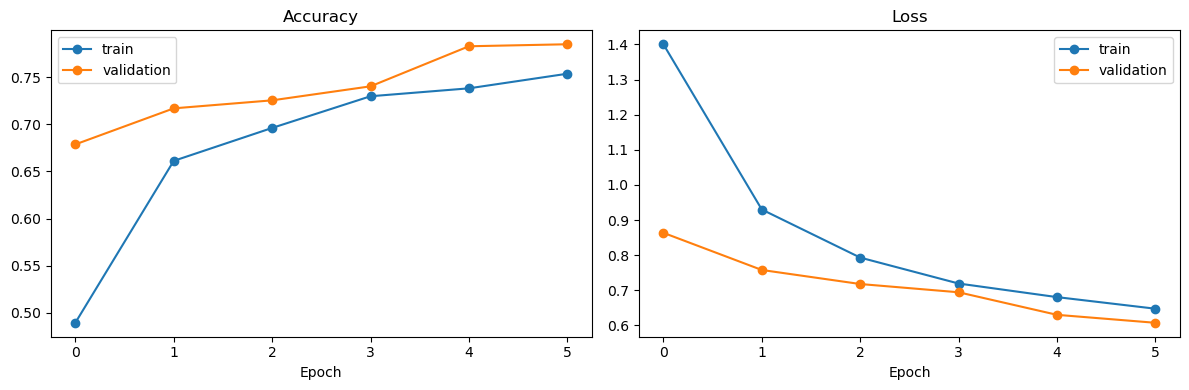

Epochs run: 6
Best epoch: 6
Train accuracy at best epoch:      0.754
Validation accuracy at best epoch: 0.785


In [52]:
#  Monitor training and validation metrics 
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history['accuracy'], marker='o', label='train')
axes[0].plot(history.history['val_accuracy'], marker='o', label='validation')
axes[0].set_title('Accuracy'); axes[0].set_xlabel('Epoch'); axes[0].legend()
axes[1].plot(history.history['loss'], marker='o', label='train')
axes[1].plot(history.history['val_loss'], marker='o', label='validation')
axes[1].set_title('Loss'); axes[1].set_xlabel('Epoch'); axes[1].legend()
plt.tight_layout()
plt.show()

best_epoch = int(np.argmin(history.history['val_loss'])) + 1
print("Epochs run:", len(history.history['loss']))
print("Best epoch:", best_epoch)
print("Train accuracy at best epoch:      %.3f" % history.history['accuracy'][best_epoch - 1])
print("Validation accuracy at best epoch: %.3f" % history.history['val_accuracy'][best_epoch - 1])

### TODO: Evaluate model performance
##### - Calculate accuracy on test set
##### - Generate confusion matrix
##### - Analyze error patterns



In [53]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

def evaluate_model(model, ds, class_names):
    """Run the model once over ds; return images, true labels, predicted labels, probabilities."""
    imgs, y_true, probs = [], [], []
    for x, y in ds:                                   # one pass: images, labels and predictions stay aligned
        probs.append(model.predict(x, verbose=0))
        y_true.append(np.argmax(y.numpy(), axis=1))
        imgs.append(x.numpy().astype('uint8'))
    probs = np.concatenate(probs)
    y_true = np.concatenate(y_true)
    imgs = np.concatenate(imgs)
    y_pred = probs.argmax(axis=1)
    return imgs, y_true, y_pred, probs

imgs, y_true, y_pred, probs = evaluate_model(model, test_dataset, class_names)

In [54]:
#  Accuracy on the test set 
print("Test images:", len(y_true))
print("Test accuracy: %.3f" % accuracy_score(y_true, y_pred))

Test images: 480
Test accuracy: 0.798


In [55]:
# Per-class precision, recall and F1 
print("\n", classification_report(y_true, y_pred, target_names=class_names, digits=3))


                      precision    recall  f1-score   support

          Cardboard      0.635     0.892     0.742        37
      Food Organics      0.966     0.778     0.862        36
              Glass      0.556     0.811     0.659        37
              Metal      0.923     0.774     0.842        93
Miscellaneous Trash      0.667     0.615     0.640        52
              Paper      0.851     0.864     0.857        66
            Plastic      0.808     0.728     0.766        81
      Textile Trash      0.841     0.860     0.851        43
         Vegetation      1.000     1.000     1.000        35

           accuracy                          0.798       480
          macro avg      0.805     0.814     0.802       480
       weighted avg      0.817     0.798     0.801       480



### Model Evaluation

The model achieved a test accuracy of **79.8%** on 480 images. It performed best on Vegetation (F1-score: 1.000), followed by Food Organics (0.862) and Paper (0.857). However, it struggled with Glass (F1-score: 0.659) and Miscellaneous Trash (0.640). Overall, the model shows good classification performance, but improving the identification of visually similar waste categories could increase its accuracy.

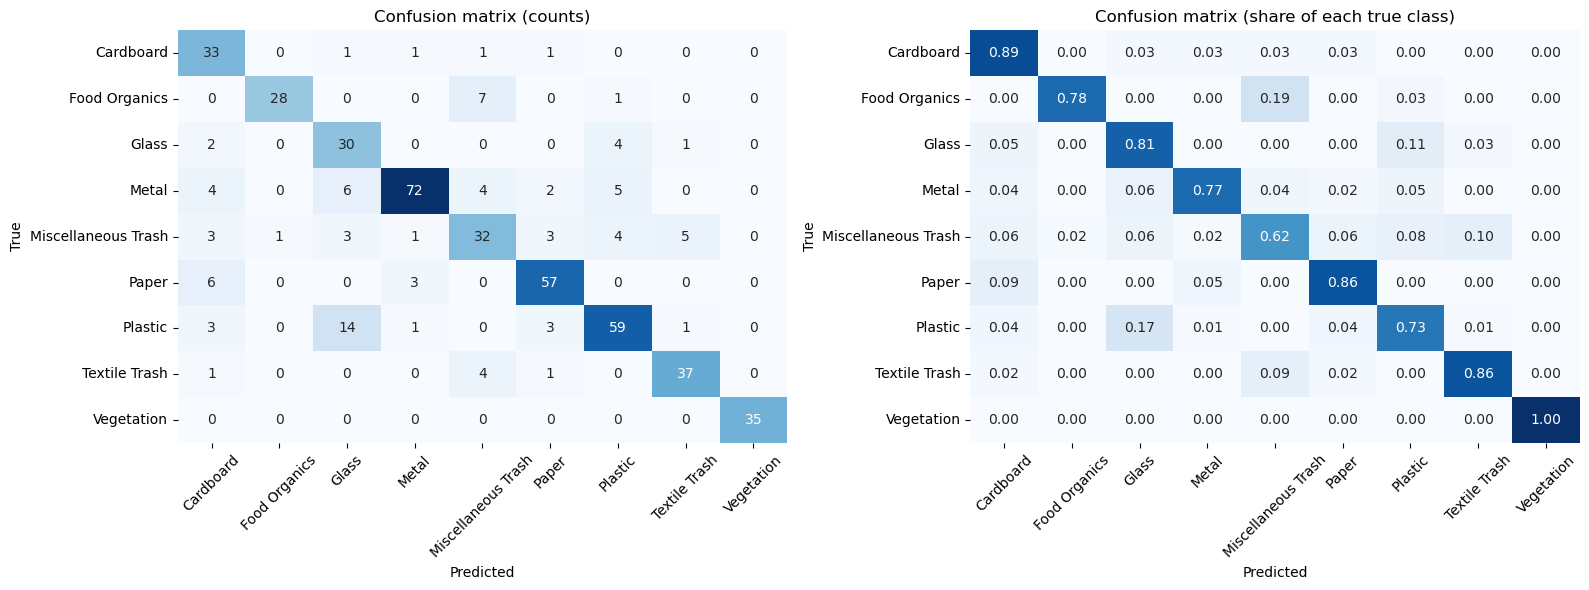

In [56]:
#  Confusion matrix (counts and row-normalised) 
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names,
            yticklabels=class_names, ax=axes[0], cbar=False)
axes[0].set_title('Confusion matrix (counts)')
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', xticklabels=class_names,
            yticklabels=class_names, ax=axes[1], cbar=False)
axes[1].set_title('Confusion matrix (share of each true class)')
for ax in axes:
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()


###  Error Analysis (confusion matrix)

- Most predictions fall on the diagonal. **Vegetation is perfect (100%)**, and Textile Trash (95%), Paper (88%), Cardboard (84%) and Food Organics (83%) are also strong.
- **Plastic is often predicted as Glass** (about 12 of 81 items, 15%). This is the biggest single confusion and explains why Glass has low precision (0.588): both are often transparent, shiny items. Plastic also loses a few items to Metal and Paper.
- **Miscellaneous Trash is the hardest class** (only 46% correct). Its errors are spread over many classes, mainly **Textile Trash (9 items, 17%)**, then Glass, Paper and Plastic. This is expected, because the class mixes many different objects.
- **Metal is confused with Plastic** (about 7 items, 8%), probably because of shiny or crushed packaging.
- **Small classes do well** (Textile Trash, Vegetation), which suggests the class weights helped. The errors come from similar-looking materials, not from class size.
- My prediction that Glass/Metal and Paper/Cardboard would be the main confusions was only partly right. The strongest confusions are **Plastic -> Glass** and **Miscellaneous Trash -> everything else**.


In [57]:
#  Error patterns: which pairs are confused most? 
errors = pd.DataFrame({'true': [class_names[i] for i in y_true],
                       'predicted': [class_names[i] for i in y_pred]})
errors = errors[errors['true'] != errors['predicted']]
pair_counts = errors.value_counts().reset_index(name='count').head(8)
print("Most common mistakes (true -> predicted):")
print(pair_counts.to_string(index=False))

Most common mistakes (true -> predicted):
               true           predicted  count
            Plastic               Glass     14
      Food Organics Miscellaneous Trash      7
              Paper           Cardboard      6
              Metal               Glass      6
Miscellaneous Trash       Textile Trash      5
              Metal             Plastic      5
              Metal Miscellaneous Trash      4
      Textile Trash Miscellaneous Trash      4


In [58]:
#  Per-class accuracy, hardest classes first 
per_class = pd.Series(np.diag(cm) / cm.sum(axis=1), index=class_names).sort_values()
print("\nRecall per class (lowest first):")
print(per_class.round(3))


Recall per class (lowest first):
Miscellaneous Trash    0.615
Plastic                0.728
Metal                  0.774
Food Organics          0.778
Glass                  0.811
Textile Trash          0.860
Paper                  0.864
Cardboard              0.892
Vegetation             1.000
dtype: float64


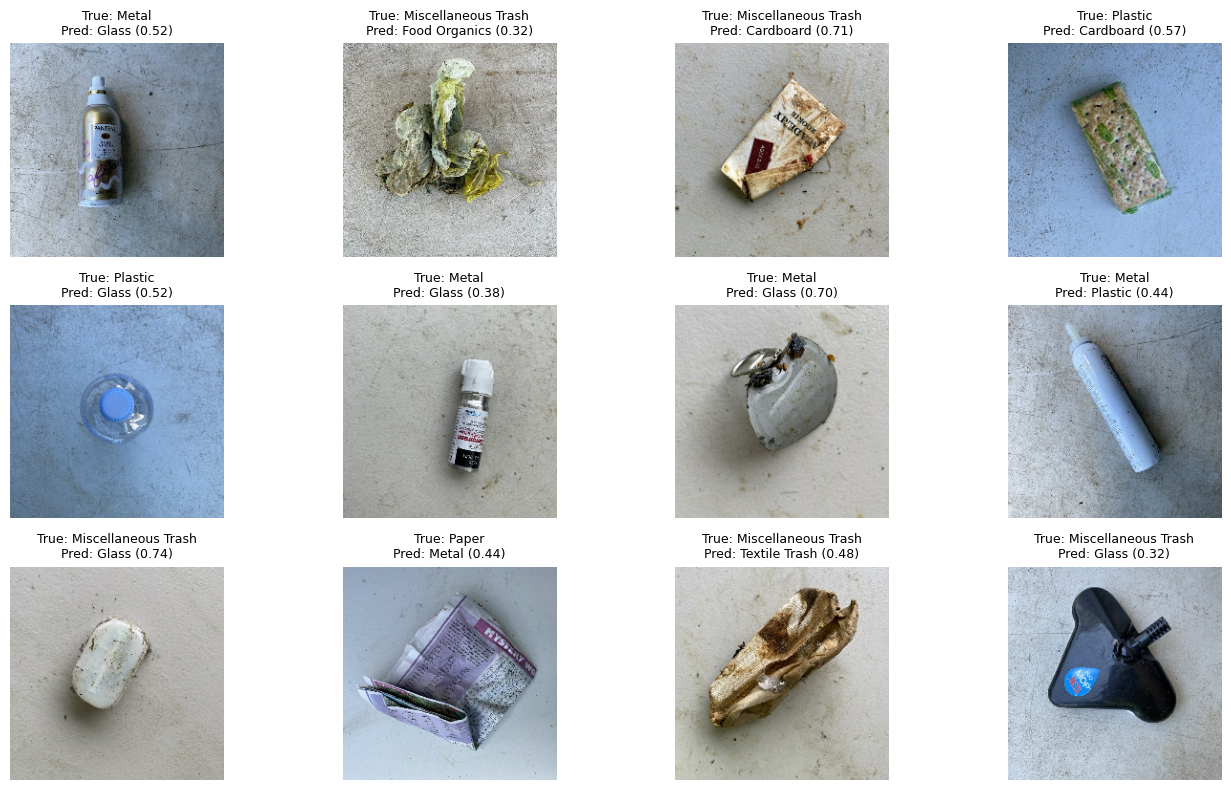

In [59]:
#  Look at some misclassified images 
wrong = np.where(y_true != y_pred)[0]
n_show = min(12, len(wrong))
picks = np.random.RandomState(42).choice(wrong, n_show, replace=False)
plt.figure(figsize=(14, 8))
for i, idx in enumerate(picks):
    plt.subplot(3, 4, i + 1)
    plt.imshow(imgs[idx])
    plt.title(f"True: {class_names[y_true[idx]]}\nPred: {class_names[y_pred[idx]]} ({probs[idx].max():.2f})",
              fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()

###  Misclassified Examples

- The 12 examples are a random sample of the model's mistakes. The number in brackets is the model's confidence.
- **Metal is the most common true class in this sample (7 of 12).** Aerosol cans, crushed cans and crumpled foil were predicted as **Glass, Plastic or Paper**. Several of these are confident mistakes (0.70 to 0.73): bottle-shaped cans look like bottles, and crushed, shiny metal looks like plastic.
- **Mixed-material and unusual items** cause errors. A bottle with a gold metal cap was predicted as Metal (true class Plastic), and a small electronic part (true class Miscellaneous Trash) was predicted as Cardboard.
  

### 2.4 Fine-tune the Model

#### TODO: Tune model parameters to improve performance
##### - Adjust learning rate
##### - Add regularization, dropout
##### - Modify architecture if needed



In [47]:
model.save_weights('head_trained.weights.h5')
import time


In [49]:
#  Helper: unfreeze the top N layers of the base model and recompile 
def prepare_finetune(n_unfreeze, lr, dropout):
    model.load_weights('head_trained.weights.h5')          # reset to the trained head
    base_model.trainable = True
    for layer in base_model.layers[:-n_unfreeze]:           # keep the lower layers frozen
        layer.trainable = False
    for layer in base_model.layers:                         # keep BatchNorm frozen (stabler)
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    for layer in model.layers:                              # change dropout in the head
        if isinstance(layer, layers.Dropout):
            layer.rate = dropout
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),   # very small learning rate
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])

In [51]:
# Experiments: change one thing at a time ----
experiments = [
    {'name': 'A: top 30 layers, lr 1e-5, dropout 0.3', 'n_unfreeze': 30, 'lr': 1e-5, 'dropout': 0.3},
    {'name': 'B: top 30 layers, lr 1e-4, dropout 0.5', 'n_unfreeze': 30, 'lr': 1e-4, 'dropout': 0.5},
]
FT_EPOCHS = 5            # lower this to 3 if time is short
results, histories = [], {}

for exp in experiments:
    print("\n=====", exp['name'], "=====")
    prepare_finetune(exp['n_unfreeze'], exp['lr'], exp['dropout'])
    t0 = time.time()
    h = model.fit(
        train_ds, validation_data=validation_ds, epochs=FT_EPOCHS,
        class_weight=class_weight_dict,
        callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=2,
                                                 restore_best_weights=True, verbose=1),
                   keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                                     patience=1, min_lr=1e-7, verbose=1)])
    histories[exp['name']] = h.history
    best = int(np.argmin(h.history['val_loss']))
    results.append({'experiment': exp['name'],
                    'epochs run': len(h.history['loss']),
                    'train acc': round(h.history['accuracy'][best], 3),
                    'val acc': round(h.history['val_accuracy'][best], 3),
                    'val loss': round(h.history['val_loss'][best], 3),
                    'minutes': round((time.time() - t0) / 60, 1)})
    model.save_weights(f"ft_{exp['name'][0]}.weights.h5")      # keep each experiment's weights


===== A: top 30 layers, lr 1e-5, dropout 0.3 =====
Epoch 1/5


C:\Users\BRIDGIT\anaconda3\AnacondA\Lib\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_1', because it has 30 variables whereas the saved optimizer has 0 variables. 
  saveable.load_own_variables(store)


119/119 ━━━━━━━━━━━━━━━━━━━━ 151s 1s/step - accuracy: 0.2054 - loss: 2.1619 - val_accuracy: 0.4170 - val_loss: 1.7837 - learning_rate: 1.0000e-05
Epoch 2/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 137s 1s/step - accuracy: 0.3651 - loss: 1.7248 - val_accuracy: 0.5468 - val_loss: 1.3991 - learning_rate: 1.0000e-05
Epoch 3/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 138s 1s/step - accuracy: 0.4503 - loss: 1.4818 - val_accuracy: 0.5936 - val_loss: 1.1787 - learning_rate: 1.0000e-05
Epoch 4/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 140s 1s/step - accuracy: 0.5145 - loss: 1.2997 - val_accuracy: 0.6404 - val_loss: 1.0526 - learning_rate: 1.0000e-05
Epoch 5/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 141s 1s/step - accuracy: 0.5555 - loss: 1.1860 - val_accuracy: 0.6553 - val_loss: 0.9707 - learning_rate: 1.0000e-05
Restoring model weights from the end of the best epoch: 5.

===== B: top 30 layers, lr 1e-4, dropout 0.5 =====
Epoch 1/5


C:\Users\BRIDGIT\anaconda3\AnacondA\Lib\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_2', because it has 30 variables whereas the saved optimizer has 0 variables. 
  saveable.load_own_variables(store)


119/119 ━━━━━━━━━━━━━━━━━━━━ 156s 1s/step - accuracy: 0.2449 - loss: 1.9909 - val_accuracy: 0.5149 - val_loss: 1.4150 - learning_rate: 1.0000e-04
Epoch 2/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 140s 1s/step - accuracy: 0.4629 - loss: 1.4010 - val_accuracy: 0.6681 - val_loss: 0.9850 - learning_rate: 1.0000e-04
Epoch 3/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 137s 1s/step - accuracy: 0.5702 - loss: 1.1154 - val_accuracy: 0.7340 - val_loss: 0.7546 - learning_rate: 1.0000e-04
Epoch 4/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 141s 1s/step - accuracy: 0.6578 - loss: 0.9280 - val_accuracy: 0.7681 - val_loss: 0.6574 - learning_rate: 1.0000e-04
Epoch 5/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7083 - loss: 0.7805
Epoch 5: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
119/119 ━━━━━━━━━━━━━━━━━━━━ 143s 1s/step - accuracy: 0.7083 - loss: 0.7805 - val_accuracy: 0.7596 - val_loss: 0.6723 - learning_rate: 1.0000e-04
Restoring model weights from the end of the best epoch: 4.


In [52]:
#  Compare with the frozen baseline 
baseline_val = 0.785
results_df = pd.DataFrame(results)
print("\nBaseline (frozen base) validation accuracy:", baseline_val)
display(results_df)


Baseline (frozen base) validation accuracy: 0.785


,experiment,epochs run,train acc,val acc,val loss,minutes
0,"A: top 30 layers, lr 1e-5, dropout 0.3",5,0.555,0.655,0.971,11.8
1,"B: top 30 layers, lr 1e-4, dropout 0.5",5,0.658,0.768,0.657,12.0


### 2.4 Fine-tuning Results

- In this run, fine-tuning the top 30 layers did **not beat the frozen baseline** (validation
  accuracy 0.785): A (lr 1e-5, dropout 0.3) reached 0.655 and B (lr 1e-4, dropout 0.5) reached
  0.768 after 5 epochs. Training accuracy was still low (0.555 and 0.658), so the unfrozen layers
  had not finished adapting.
- An earlier run of the same experiments reached 0.817 (A) and 0.800 (B), so results vary a lot
  between runs. The validation set has only 470 images, and the seeds were not fixed.
- Fine-tuning therefore gave no reliable gain over the frozen model, and the baseline's test
  accuracy (0.798) is the dependable CNN result. The Part 5 assistant uses the saved `ft_A`
  weights from the earlier run, which score about 0.80 on the test images, the same as the baseline.


## Part 3: Waste Description Classification

In this section, you will build a text classification model to categorize waste based on descriptions.

### 3.1 Preprocess Text Data

#### TODO: Implement text preprocessing
##### - Apply the text preprocessing pipeline created earlier


In [53]:
# Before / after cleaning 
examples = df_clean.sample(6, random_state=1)[['description', 'clean_text', 'category']]
display(examples)

,description,clean_text,category
3388,folded wrapping paper,folded wrapping paper,Paper
1537,dry orange Designer light bulb with contents,dry orange designer light bulb with contents,Glass
1771,crumpled fun-sized silver avocado pit with pro...,crumpled fun sized silver avocado pit with pro...,Food Organics
3121,dirty flower petals,dirty flower petals,Vegetation
3858,used glass candle holder,used glass candle holder,Glass
4006,enormous Budget egg shells with product remaining,enormous budget egg shells with product remaining,Food Organics


In [54]:
# Summary of the preprocessed data 
print("Rows after de-duplication:", len(df_clean))
print("Train / Validation / Test:", len(X_train), "/", len(X_val), "/", len(X_test))
print("TF-IDF shapes:", X_train_tfidf.shape, X_val_tfidf.shape, X_test_tfidf.shape)
print("Classes:", list(le.classes_))

Rows after de-duplication: 4939
Train / Validation / Test: 3457 / 741 / 741
TF-IDF shapes: (3457, 2380) (741, 2380) (741, 2380)
Classes: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']


In [55]:
print("\nEmpty cleaned texts:", (df_clean['clean_text'].str.len() == 0).sum())
print("Texts shared by train and test:", len(set(X_train) & set(X_test)))


Empty cleaned texts: 0
Texts shared by train and test: 0


In [56]:
# Which words does TF-IDF weight most? (the most informative words)
import numpy as np
mean_tfidf = np.asarray(X_train_tfidf.mean(axis=0)).ravel()
top = pd.Series(mean_tfidf, index=tfidf.get_feature_names_out()).nlargest(15)
print("\nTop weighted terms:\n", top.round(3))


Top weighted terms:
 with       0.023
sized      0.020
glass      0.019
bottle     0.017
empty      0.017
box        0.016
paper      0.016
food       0.014
plastic    0.014
metal      0.013
residue    0.013
dry        0.012
brand      0.011
stained    0.011
new        0.011
dtype: float64


### 3.2 Implement Text Classification Model

### TODO: Choose and implement a text classification model
##### Option A: Traditional ML model (Naive Bayes, Random Forest, etc.)
##### Option B: Fine-tune a transformer-based model (BERT, DistilBERT, etc.)



In [57]:
import time
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

models = {
    'Naive Bayes':         MultinomialNB(alpha=0.1),
    'Logistic Regression': LogisticRegression(max_iter=1000, C=10, random_state=42),
    'Linear SVM':          LinearSVC(C=1.0, random_state=42),
    'Random Forest':       RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
}

rows = []
for name, clf in models.items():
    t0 = time.time()
    clf.fit(X_train_tfidf, y_train)
    pred_val = clf.predict(X_val_tfidf)
    rows.append({'model': name,
                 'train acc': round(accuracy_score(y_train, clf.predict(X_train_tfidf)), 3),
                 'val acc': round(accuracy_score(y_val, pred_val), 3),
                 'val macro F1': round(f1_score(y_val, pred_val, average='macro'), 3),
                 'seconds': round(time.time() - t0, 1)})
results_text = pd.DataFrame(rows).sort_values('val acc', ascending=False).reset_index(drop=True)
display(results_text)

,model,train acc,val acc,val macro F1,seconds
0,Linear SVM,1.000,1.000,1.000,0.3
1,Logistic Regression,1.000,0.996,0.996,0.5
2,Naive Bayes,0.999,0.982,0.983,0.1
3,Random Forest,1.000,0.978,0.979,2.5



- All four TF-IDF models score **very high (0.978 to 1.000)** on the validation set, and they train in seconds. This fits what the data exploration showed: the descriptions are short, templated and use a small vocabulary (309 words), so the words themselves almost give the category away.
- **Linear SVM** is perfect on validation (1.000), followed closely by **Logistic Regression** (0.996, about 3 mistakes in 741). **Naive Bayes** (0.982) and **Random Forest** (0.978) are slightly weaker, and Random Forest is also the slowest.
- Training accuracy is about 1.000 for every model, and the gap to validation is at most 2 points, so there is **little overfitting**. The small gap for Naive Bayes and Random Forest is the main difference between the models.
- **Selected model: Logistic Regression**, even though the SVM scored higher. The difference is about 3 validation texts, which is within noise, and Logistic Regression gives **class probabilities** (`predict_proba`), which I need for the confidence score and low-confidence handling in the integrated assistant. `LinearSVC` does not provide them.


In [58]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

grid_rows = []
for ngram in [(1, 1), (1, 2), (1, 3)]:
    for min_df in [1, 2]:
        for C in [1, 10, 100]:
            pipe = Pipeline([
                ('tfidf', TfidfVectorizer(ngram_range=ngram, min_df=min_df)),
                ('clf', LogisticRegression(C=C, max_iter=1000, random_state=42))])
            pipe.fit(X_train, y_train)                       # raw cleaned text in, features built inside
            pred = pipe.predict(X_val)
            grid_rows.append({'ngram': ngram, 'min_df': min_df, 'C': C,
                              'val acc': round(accuracy_score(y_val, pred), 4),
                              'val macro F1': round(f1_score(y_val, pred, average='macro'), 4)})

grid_df = pd.DataFrame(grid_rows).sort_values(['val acc', 'val macro F1'], ascending=False).reset_index(drop=True)
display(grid_df.head(10))

best = grid_df.iloc[0]
best_pipe = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=best['ngram'], min_df=int(best['min_df']))),
    ('clf', LogisticRegression(C=float(best['C']), max_iter=1000, random_state=42))])
best_pipe.fit(X_train, y_train)
print("Best settings:", dict(best))

,ngram,min_df,C,val acc,val macro F1
0,"(1, 1)",1,10,1.0000,1.0000
1,"(1, 1)",1,100,1.0000,1.0000
2,"(1, 1)",2,10,1.0000,1.0000
3,"(1, 1)",2,100,1.0000,1.0000
4,"(1, 2)",2,100,0.9973,0.9973
5,"(1, 3)",2,100,0.9973,0.9973
6,"(1, 2)",1,100,0.9960,0.9960
7,"(1, 2)",2,10,0.9960,0.9960
8,"(1, 2)",1,10,0.9946,0.9946
9,"(1, 3)",2,10,0.9946,0.9946


Best settings: {'ngram': (1, 1), 'min_df': np.int64(1), 'C': np.int64(10), 'val acc': np.float64(1.0), 'val macro F1': np.float64(1.0)}


Test accuracy: 0.999
                     precision    recall  f1-score   support

          Cardboard      1.000     1.000     1.000        87
      Food Organics      1.000     1.000     1.000        76
              Glass      1.000     1.000     1.000        81
              Metal      1.000     1.000     1.000        75
Miscellaneous Trash      1.000     1.000     1.000        87
              Paper      1.000     1.000     1.000        75
            Plastic      0.988     1.000     0.994        84
      Textile Trash      1.000     0.989     0.994        88
         Vegetation      1.000     1.000     1.000        88

           accuracy                          0.999       741
          macro avg      0.999     0.999     0.999       741
       weighted avg      0.999     0.999     0.999       741



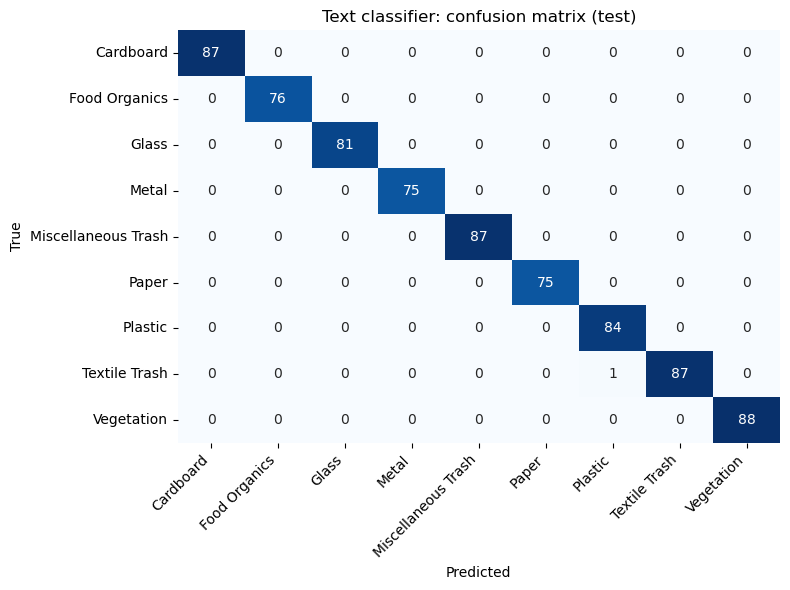

Misclassified: 1 of 741


,description,true,predicted,confidence
5,torn industrial purple plastic rug partially f...,Textile Trash,Plastic,0.48


In [59]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

pred_test = best_pipe.predict(X_test)
print("Test accuracy: %.3f" % accuracy_score(y_test, pred_test))
print(classification_report(y_test, pred_test, target_names=le.classes_, digits=3))

cm = confusion_matrix(y_test, pred_test)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_, cbar=False)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Text classifier: confusion matrix (test)')
plt.xticks(rotation=45, ha='right'); plt.tight_layout(); plt.show()

# Misclassified descriptions
err = pd.DataFrame({'description': X_test.values,
                    'true': le.inverse_transform(y_test),
                    'predicted': le.inverse_transform(pred_test),
                    'confidence': best_pipe.predict_proba(X_test).max(axis=1).round(2)})
err = err[err['true'] != err['predicted']]
print("Misclassified:", len(err), "of", len(y_test))
display(err.sort_values('confidence', ascending=False).head(15))



- The tuned TF-IDF + Logistic Regression model classified **740 of 741 test descriptions correctly (accuracy about 0.999)**. The confusion matrix is almost perfectly diagonal, with every class between 75 and 88 correct.
- **There is only one error:** a *Textile Trash* description ("torn industrial purple plastic rug partially f...") was predicted as *Plastic*. The cause is clear: the description contains the word **"plastic"**, which is a strong Plastic keyword, and the model followed it instead of the item word "rug". The item is a rug, so the true label is Textile Trash.
- The model was **uncertain** about this case (confidence **0.48**, much lower than a typical confident prediction), so a confidence threshold in the assistant could flag it for a follow-up question instead of answering directly.
- This shows how the model works: it relies mostly on **individual material words** and has little understanding of the whole phrase. Descriptions that mix a material word with a different item word (for example "plastic rug" or "paper bag with metal clip") are the cases most likely to fail.


In [60]:
rng = np.random.RandomState(42)

def add_typos(text, p=0.3):
    out = []
    for w in text.split():
        if len(w) > 3 and rng.rand() < p:
            i = rng.randint(1, len(w) - 1)
            w = w[:i] + w[i + 1:] if rng.rand() < 0.5 else w[:i] + w[i + 1] + w[i] + w[i + 2:]   # delete or swap
        out.append(w)
    return ' '.join(out)

SYN = {'can': 'tin', 'box': 'carton', 'bottle': 'flask', 'bag': 'sack', 'clothing': 'garment', 'paper': 'sheet'}
def swap_synonyms(text):
    return ' '.join(SYN.get(w, w) for w in text.split())

tests = {'clean': X_test,
         'typos': X_test.apply(add_typos),
         'synonyms': X_test.apply(swap_synonyms)}
rows = []
for name, texts in tests.items():
    rows.append({'test set': name, 'accuracy': round(accuracy_score(y_test, best_pipe.predict(texts)), 3)})
display(pd.DataFrame(rows))
print(pd.DataFrame({'original': X_test.head(5).values, 'typos': tests['typos'].head(5).values}))

,test set,accuracy
0,clean,0.999
1,typos,0.870
2,synonyms,0.980


                                            original  \
0                            full patterned branches   
1                        full regular sized corn cob   
2                     intact red palm fronds leaking   
3                         dry compact bush clippings   
4  dirty tiny patterned rubber generic baby cloth...   

                                               typos  
0                            full patterned branches  
1                         full reglar sized corn cob  
2                       intct red palm fronds leakng  
3                         dry compact bush clippings  
4  diry tiy patterned rubber geneirc bbay clothes...  


In [61]:
def classify_with_confidence(description):
    """Return (predicted category, confidence) for a waste description.
    Returns (None, 0.0) for empty or invalid input."""
    if not isinstance(description, str) or not description.strip():
        return None, 0.0                              # empty or invalid input
    cleaned = clean_text(description)
    if not cleaned:
        return None, 0.0
    probs = best_pipe.predict_proba([cleaned])[0]
    idx = int(probs.argmax())
    return le.classes_[idx], float(round(probs[idx], 3))

for t in ["empty glass bottle", "crushed alumnium can", "dirty cardboard box", "", "xyz"]:
    print(repr(t), "->", classify_with_confidence(t))

'empty glass bottle' -> ('Glass', 1.0)
'crushed alumnium can' -> ('Metal', 0.999)
'dirty cardboard box' -> ('Cardboard', 1.0)
'' -> (None, 0.0)
'xyz' -> ('Textile Trash', 0.202)


### classify_with_confidence

- Clear descriptions are classified with **very high confidence (0.999 to 1.000)**.
- The empty string returns `(None, 0.0)` and does not crash.
- The misspelled "alumnium" was still classified as Metal. The model does not know that word, so it most likely relied on "crushed" and "can". This shows tolerance to a typo when the rest of the description is informative, but it does not prove the model understands misspellings.
- **Nonsense input ("xyz") still gets a category**, because the model must choose one of the 9 classes. Its confidence is only **0.202**, far below the 0.999 to 1.000 for real descriptions, so a confidence threshold can reject it.

### 3.3 Train and Evaluate the Model

### TODO: Train the text classification model
##### - Use appropriate training parameters
##### - Monitor training progress



In [62]:
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score, learning_curve
from sklearn.metrics import accuracy_score, f1_score

In [75]:
# Training parameters (chosen from the comparison and tuning cells) 
PARAMS = dict(
    word_ngrams=(1, 2),      # single words and word pairs
    char_ngrams=(2, 5),      # pieces of words, so misspellings still match
    C=10,                    # regularisation strength (higher = less regularisation)
    max_iter=2000)

text_model = Pipeline([
    ('features', FeatureUnion([
        ('word', TfidfVectorizer(ngram_range=PARAMS['word_ngrams'], min_df=1)),
        ('char', TfidfVectorizer(analyzer='char_wb', ngram_range=PARAMS['char_ngrams'], min_df=2)),
    ])),
    ('clf', LogisticRegression(C=PARAMS['C'], max_iter=PARAMS['max_iter'], random_state=42)),
])


In [76]:
# Train on the TRAINING set only 
text_model.fit(X_train, y_train)
print("Solver iterations used:", text_model.named_steps['clf'].n_iter_[0], "of", PARAMS['max_iter'])
print("Number of features:", len(text_model.named_steps['features'].get_feature_names_out()))


Solver iterations used: 35 of 2000
Number of features: 8640


In [77]:
#  Monitor: training vs validation 
train_pred = text_model.predict(X_train)
val_pred = text_model.predict(X_val)
print("Train accuracy:      %.3f" % accuracy_score(y_train, train_pred))
print("Validation accuracy: %.3f" % accuracy_score(y_val, val_pred))
print("Validation macro F1: %.3f" % f1_score(y_val, val_pred, average='macro'))

Train accuracy:      1.000
Validation accuracy: 0.996
Validation macro F1: 0.996


In [78]:
 # Monitor: 5-fold cross-validation on the training set (how stable is it?) 
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(text_model, X_train, y_train, cv=cv, scoring='accuracy', n_jobs=-1)
print("5-fold CV accuracy: %.3f (+/- %.3f)" % (cv_scores.mean(), cv_scores.std()))

5-fold CV accuracy: 0.998 (+/- 0.001)


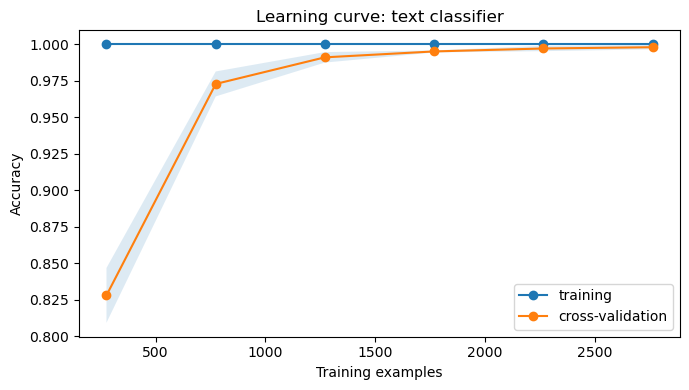

In [79]:
# Monitor: learning curve (accuracy as the training set grows) 
sizes, tr_scores, va_scores = learning_curve(
    text_model, X_train, y_train, cv=cv, scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1, random_state=42)

plt.figure(figsize=(7, 4))
plt.plot(sizes, tr_scores.mean(axis=1), marker='o', label='training')
plt.plot(sizes, va_scores.mean(axis=1), marker='o', label='cross-validation')
plt.fill_between(sizes, va_scores.mean(axis=1) - va_scores.std(axis=1),
                 va_scores.mean(axis=1) + va_scores.std(axis=1), alpha=0.15)
plt.xlabel('Training examples'); plt.ylabel('Accuracy')
plt.title('Learning curve: text classifier'); plt.legend(); plt.tight_layout(); plt.show()

### Learning Curve

- **Training accuracy stays at 1.000** for every training size, so the model fits whatever data it sees perfectly.
- **Cross-validation accuracy rises quickly:** about **0.83** with roughly 300 examples, about **0.97** with 800, and about **0.99 or higher** from around 1,300 examples. It ends close to **0.998** with about 2,800.
- **The gap between the two curves shrinks to almost nothing**, so the model **generalises well** and is not overfitting.
- **The curve has flattened.** After about 1,500 examples, extra data adds very little (less than half a point), so collecting more of this kind of data would not help.
- **The shaded band (the spread between folds) is wide at the start and almost disappears later**, so results are stable once there are enough examples.
- **Why it learns so fast:** the descriptions are short and templated, with a small vocabulary, so a few hundred examples already cover most of the patterns. This is another sign that the dataset is easy and not that the problem is easy in real life.

### TODO: Evaluate model performance
##### - Calculate accuracy on test set
##### - Generate confusion matrix
##### - Analyze error patterns



In [80]:
#  Accuracy on the test set 
pred_test = text_model.predict(X_test)
probs_test = text_model.predict_proba(X_test)
print("Test descriptions:", len(y_test))
print("Test accuracy: %.3f" % accuracy_score(y_test, pred_test))
print("Test macro F1: %.3f" % f1_score(y_test, pred_test, average='macro'))

Test descriptions: 741
Test accuracy: 0.993
Test macro F1: 0.993


In [81]:
# Per-class precision, recall, F1 
print("\n", classification_report(y_test, pred_test, target_names=le.classes_, digits=3))



                      precision    recall  f1-score   support

          Cardboard      1.000     1.000     1.000        87
      Food Organics      1.000     1.000     1.000        76
              Glass      0.953     1.000     0.976        81
              Metal      1.000     1.000     1.000        75
Miscellaneous Trash      1.000     0.977     0.988        87
              Paper      1.000     1.000     1.000        75
            Plastic      0.988     1.000     0.994        84
      Textile Trash      1.000     0.966     0.983        88
         Vegetation      1.000     1.000     1.000        88

           accuracy                          0.993       741
          macro avg      0.993     0.994     0.993       741
       weighted avg      0.994     0.993     0.993       741



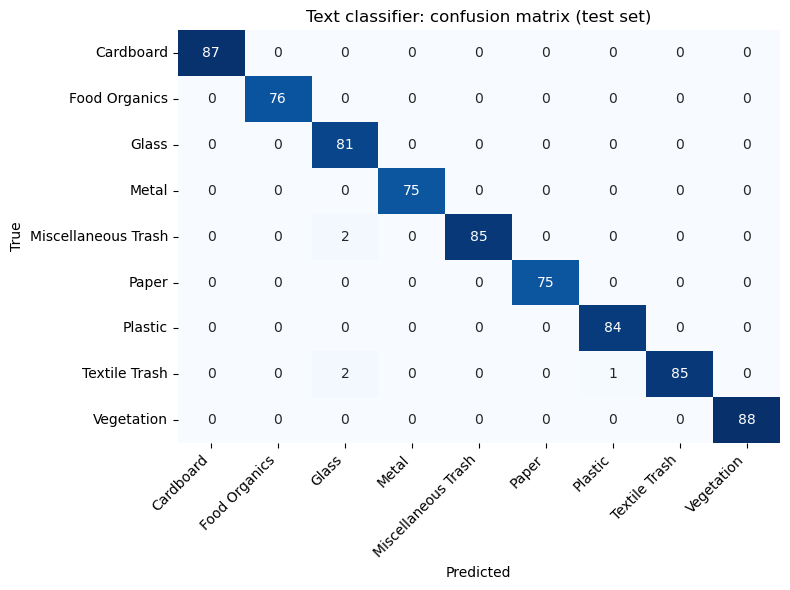

In [82]:
# Confusion matrix 
cm = confusion_matrix(y_test, pred_test)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_, cbar=False)
plt.xlabel('Predicted'); plt.ylabel('True')
plt.title('Text classifier: confusion matrix (test set)')
plt.xticks(rotation=45, ha='right'); plt.tight_layout(); plt.show()

In [83]:
#  Error patterns: every misclassified description 
errors = pd.DataFrame({
    'description': X_test.values,
    'true': le.inverse_transform(y_test),
    'predicted': le.inverse_transform(pred_test),
    'confidence': probs_test.max(axis=1).round(2)})
wrong = errors[errors['true'] != errors['predicted']]
print("Misclassified: %d of %d" % (len(wrong), len(errors)))
pd.set_option('display.max_colwidth', None)
display(wrong.sort_values('confidence', ascending=False))

Misclassified: 5 of 741


,description,true,predicted,confidence
196,medium glass rug,Textile Trash,Glass,0.74
5,torn industrial purple plastic rug partially filled,Textile Trash,Plastic,0.64
45,personal green glass eco friendly marker,Miscellaneous Trash,Glass,0.50
378,oversized glass eco friendly rug with product remaining,Textile Trash,Glass,0.49
540,striped glass toy with food residue,Miscellaneous Trash,Glass,0.48


In [84]:
#  Confidence: are mistakes less confident than correct predictions? 
correct_conf = errors.loc[errors['true'] == errors['predicted'], 'confidence']
print("\nMean confidence, correct predictions: %.2f" % correct_conf.mean())
if len(wrong):
    print("Mean confidence, wrong predictions:   %.2f" % wrong['confidence'].mean())
print("Correct predictions below 0.5 confidence:", int((correct_conf < 0.5).sum()))



Mean confidence, correct predictions: 0.96
Mean confidence, wrong predictions:   0.57
Correct predictions below 0.5 confidence: 1


In [85]:
#  Lowest-confidence correct predictions 
display(errors[errors['true'] == errors['predicted']].sort_values('confidence').head(10))

,description,true,predicted,confidence
586,dirty small plastic budget tool,Miscellaneous Trash,Miscellaneous Trash,0.49
254,large paper bed sheet,Textile Trash,Textile Trash,0.54
275,crumpled metal designer toy with product remaining,Miscellaneous Trash,Miscellaneous Trash,0.58
199,full massive floral toy with product remaining,Miscellaneous Trash,Miscellaneous Trash,0.62
39,crumpled massive gold cardboard battery,Miscellaneous Trash,Miscellaneous Trash,0.65
452,torn metal artisanal fabric scrap,Textile Trash,Textile Trash,0.72
224,industrial blue bottle cap containing residue,Metal,Metal,0.76
119,new small pink artisanal cd case,Plastic,Plastic,0.76
416,wet travel sized transparent natural dryer lint containing residue,Miscellaneous Trash,Miscellaneous Trash,0.76
229,wrinkled standard blue eco friendly vegetable waste with label attached,Food Organics,Food Organics,0.77


### Test Evaluation and Error Analysis

- **Test accuracy: 0.993** (macro F1 0.993) on 741 test descriptions, with **5 mistakes**. The test set was used only after the model was chosen and tuned on the validation set.
- **The 5 mistakes** all follow the same pattern: a material word in the description outweighs the item word.
Four of the five contain the word **"glass"** and one contains **"plastic"**, but the item is a rug, a marker or a toy. The model follows the material word and ignores the item word.
- **Confidence separates right from wrong, but not completely:**
  - Correct predictions have a mean confidence of **0.96**, and wrong ones only **0.57**.
  - Only **1** correct prediction fell below 0.5.
  - A **confidence threshold of 0.5** would flag only the two least confident mistakes (0.49 and 0.48), and the one at 0.50 is on the border. Two of the mistakes (0.74 and 0.64) are above the threshold and would still be answered wrongly. The threshold helps, but it does not catch every error.
- **The hardest correct cases show the same weakness.** The lowest-confidence correct predictions mix a material word with an unrelated item:
  - "large **paper** bed sheet" (Textile Trash, 0.54)
  - "crumpled **metal** designer toy" (Miscellaneous Trash, 0.58)
  - "crumpled gold **cardboard** battery" (Miscellaneous Trash, 0.65)
  - "torn **metal** artisanal fabric scrap" (Textile Trash, 0.72)
- **Textile Trash and Miscellaneous Trash are the affected classes**, because their items (rugs, toys, markers, batteries) are described with material words that belong to other classes. The model relies on material words and can be misled when the material and the item point to different classes.
- **Limitation:** the data is short and templated, so real-world accuracy will be lower. The typo stress test (accuracy **0.870** for the word-only model, against 0.999 on clean text) shows how sensitive these models are to unseen wording.

### 3.4 Create Classification Function

In [125]:
# TODO: Create a function that takes a text description and returns the predicted waste category

def classify_waste_description(description):
    """
    Classifies a waste description into an appropriate category.

    Args:
        description (str): Text description of waste item

    Returns:
        str: Predicted waste category
    """
    # Return "Unknown" for empty or non-text input
    if not isinstance(description, str) or not description.strip():
        return "Unknown"

    # Clean the text the same way as in training
    cleaned = clean_text(description)
    if not cleaned:
        return "Unknown"

    # Predict probabilities and pick the most likely class
    probs = text_model.predict_proba([cleaned])[0]
    idx = int(np.argmax(probs))

    # Return "Unknown" if the model is not confident (below 0.5)
    if probs[idx] < 0.5:
        return "Unknown"

    return le.inverse_transform([text_model.classes_[idx]])[0]
    

## Part 4: Recycling Instruction Generation with RAG

In this section, you will implement a Retrieval-Augmented Generation (RAG) system to generate recycling instructions.

### 4.1 Preprocess Documents for Retrieval

### TODO: Prepare documents for retrieval
##### - Process policy documents and disposal instructions
##### - Create embeddings for efficient retrieval



In [52]:

%pip install -q torch transformers sentencepiece sentence-transformers

Note: you may need to restart the kernel to use updated packages.


In [53]:
import os

# Stop transformers from loading TensorFlow (avoids Keras 3 conflicts with your CNN setup)
os.environ["USE_TF"] = "0"
os.environ["USE_FLAX"] = "0"

# Make sure offline mode is OFF so models can download
os.environ.pop("HF_HUB_OFFLINE", None)
os.environ.pop("TRANSFORMERS_OFFLINE", None)

In [54]:
import importlib, sys
print("Python:", sys.version.split()[0])
for pkg in ["numpy", "pandas", "sklearn", "torch", "transformers",
            "sentence_transformers", "sentencepiece", "tensorflow", "PIL"]:
    try:
        m = importlib.import_module(pkg)
        print(f"{pkg:22s} OK  {getattr(m, '__version__', '')}")
    except Exception as e:
        print(f"{pkg:22s} MISSING -> {str(e)[:60]}")

import urllib.request
try:
    print("huggingface.co:", urllib.request.urlopen("https://huggingface.co", timeout=10).status)
except Exception as e:
    print("huggingface.co NOT reachable:", e)

Python: 3.13.9
numpy                  OK  2.3.5
pandas                 OK  2.3.3
sklearn                OK  1.7.2
torch                  OK  2.14.1+cpu
transformers           OK  5.20.2
sentence_transformers  OK  6.2.0
sentencepiece          OK  0.2.2
tensorflow             OK  2.21.0
PIL                    OK  12.0.0
huggingface.co: 200


In [55]:
# Policy chunks from Part 1.3 
policy_chunks = chunks_df.drop(columns='embed_text', errors='ignore').copy()

# Disposal instructions from waste_descriptions.csv (one row per distinct instruction)
disp = (df_clean[['category', 'disposal_instruction']]
        .dropna().drop_duplicates().reset_index(drop=True))
disp_chunks = pd.DataFrame({
    'policy_id': -1,                      # -1 = not from a policy document
    'policy_type': 'Disposal instruction',
    'doc_kind': 'disposal',
    'category': disp['category'],
    'section': 'Disposal Instruction',
    'effective_date': None,
    'text': disp['disposal_instruction']})

kb = pd.concat([policy_chunks, disp_chunks], ignore_index=True)
print("Knowledge base:", kb.shape)
print(kb.doc_kind.value_counts().to_dict())

Knowledge base: (112, 7)
{'disposal': 45, 'single': 44, 'multi': 23}


In [56]:
def split_items(text):
    """Chunk text is joined with '; ' (see chunk_document). Return clean items."""
    return [i.strip() for i in text.split(';') if i.strip()]

# Items explicitly excluded by single-category 'Non-Acceptable Items' sections
excluded = {}
mask = (kb.doc_kind == 'single') & kb.section.str.contains('Non-Acceptable', case=False)
for _, r in kb[mask].iterrows():
    excluded.setdefault(r.category, set()).update(i.lower() for i in split_items(r.text))

# Remove those items from the multi-category summaries
removed = []
def strip_excluded(row):
    if row.doc_kind != 'multi':
        return row.text
    keep = []
    for item in split_items(row.text):
        if item.lower() in excluded.get(row.category, set()):
            removed.append((row.policy_id, row.category, item))
        else:
            keep.append(item)
    return '; '.join(keep)

kb['text'] = kb.apply(strip_excluded, axis=1)
kb = kb[kb.text.str.len() > 0].reset_index(drop=True)    # drop chunks that became empty

# Text that will be embedded: category + section give each chunk its context
kb['embed_text'] = kb['category'] + ' - ' + kb['section'] + ': ' + kb['text']

print("Conflicting items removed from multi-category documents:", len(removed))
for r in removed:
    print("  policy", r[0], "|", r[1], "|", r[2])

Conflicting items removed from multi-category documents: 4
  policy 10 | Plastic | Plastic bags and film
  policy 11 | Plastic | Plastic bags and film
  policy 11 | Glass | Window glass or mirrors
  policy 13 | Glass | Window glass or mirrors


In [57]:
multi = kb[kb.doc_kind == 'multi']
for phrase in ["window glass or mirrors", "plastic bags and film"]:
    still = multi[multi.text.str.lower().str.contains(phrase)]
    print(f"'{phrase}' still in multi-category chunks:", len(still))

'window glass or mirrors' still in multi-category chunks: 0
'plastic bags and film' still in multi-category chunks: 0


In [58]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize

# Sparse: TF-IDF (unigrams + bigrams)
kb_vec = TfidfVectorizer(ngram_range=(1, 2), stop_words='english', sublinear_tf=True)
kb_tfidf = kb_vec.fit_transform(kb['embed_text'])

# Dense: LSA (TruncatedSVD on TF-IDF), no download needed
svd = TruncatedSVD(n_components=60, random_state=42)
dense_emb = normalize(svd.fit_transform(kb_tfidf))
encode_query = lambda q: normalize(svd.transform(kb_vec.transform([q])))[0]
USE_DENSE, DENSE_KIND = True, 'LSA (TruncatedSVD on TF-IDF)'

print("Chunks:", len(kb), "| TF-IDF:", kb_tfidf.shape, "| Dense:", DENSE_KIND, dense_emb.shape)

Chunks: 112 | TF-IDF: (112, 1050) | Dense: LSA (TruncatedSVD on TF-IDF) (112, 60)


In [59]:
EXPAND = {'not accepted': 'non-acceptable items', 'not allowed': 'non-acceptable items',
          'cannot': 'non-acceptable items', 'accepted': 'acceptable items',
          'prepare': 'preparation instructions', 'clean': 'preparation instructions',
          'pick up': 'collection method', 'collected': 'collection method'}

def expand_query(q):
    return q + ' ' + ' '.join(v for k, v in EXPAND.items() if k in q.lower())

def hybrid_retrieve(query, category=None, k=3, alpha=0.6, boost=0.05, expand=True):
    """Dense (LSA) + sparse (TF-IDF) score, small boost for complete single-category
    policies, optional filter on the predicted category."""
    q = expand_query(query) if expand else query
    sparse = (kb_tfidf @ kb_vec.transform([q]).T).toarray().ravel()
    dense = dense_emb @ encode_query(q)
    s = alpha * dense + (1 - alpha) * sparse + boost * (kb.doc_kind == 'single').values
    if category is not None:
        s = np.where((kb.category == category).values, s, -1)
    top = np.argsort(s)[::-1][:k]
    out = kb.iloc[top][['policy_id', 'doc_kind', 'category', 'section', 'text']].copy()
    out['score'] = s[top].round(3)
    return out

def retrieve_for_category(category):
    """Structured retrieval: the category's policy sections + one disposal instruction."""
    policy = kb[(kb.category == category) & (kb.doc_kind == 'single')
                & (~kb.section.isin(['Benefits', 'Overview']))]
    disposal = kb[(kb.category == category) & (kb.doc_kind == 'disposal')].head(1)
    return pd.concat([policy, disposal])[['policy_id', 'doc_kind', 'category', 'section', 'text']]

In [60]:
for q, cat in [("Can I recycle window glass?", "Glass"),
               ("How do I prepare plastic bottles?", "Plastic"),
               ("What items are not accepted for textile recycling?", "Textile Trash")]:
    print("\nQUERY:", q)
    display(hybrid_retrieve(q, category=cat, k=3))


QUERY: Can I recycle window glass?


,policy_id,doc_kind,category,section,text,score
6,2,single,Glass,Non-Acceptable Items,Window glass or mirrors; Drinking glasses; Cer...,0.646
8,2,single,Glass,Preparation Instructions,Rinse containers; Remove caps and lids (recycl...,0.386
5,2,single,Glass,Acceptable Items,Glass bottles (all colors); Glass jars; Glass ...,0.355



QUERY: How do I prepare plastic bottles?


,policy_id,doc_kind,category,section,text,score
18,4,single,Plastic,Preparation Instructions,Rinse containers; Remove lids and caps (recycl...,0.533
15,4,single,Plastic,Acceptable Items,PET bottles and containers (code #1); HDPE con...,0.285
49,11,multi,Plastic,PLASTIC GUIDELINES,PET bottles and containers (code #1); HDPE con...,0.248



QUERY: What items are not accepted for textile recycling?


,policy_id,doc_kind,category,section,text,score
1,1,single,Textile Trash,Non-Acceptable Items,Wet or moldy textiles; Heavily soiled items; C...,0.491
2,1,single,Textile Trash,Collection Method,Place items in dedicated textile recycling bin...,0.409
4,1,single,Textile Trash,Benefits,Textile recycling conserves resources and redu...,0.338


### Findings: Retrieval Sanity Checks (hybrid retriever)

- I tested the hybrid retriever (TF-IDF + LSA dense vectors, query expansion, and a small boost for single-category documents) on 3 queries, each filtered to the expected category.
- **All 3 queries returned the right section first.**
  - *Window glass:* Glass **Non-Acceptable Items** (policy 2) ranked first with a score of 0.646, well ahead of the next result (0.386). The resident gets the exclusion, not the list of accepted items.
  - *Preparing plastic bottles:* Plastic **Preparation Instructions** (policy 4) ranked first (0.533), ahead of Acceptable Items (0.285).
  - *Textile "not accepted":* Textile Trash **Non-Acceptable Items** (policy 1) ranked first (0.491).
- **Query expansion fixed the wording mismatch** The baseline retriever missed "not accepted" and "prepare", but expansion maps them to the section names *Non-Acceptable Items* and *Preparation Instructions*.


### 4.2 Implement RAG-based System

### TODO: Select a pre-trained language model and implement RAG
##### - Choose an appropriate language model
##### - Create a retrieval mechanism



In [53]:
import time


MODEL_NAME = "google/flan-t5-small"
TRY_DOWNLOAD_LM = False     # set True once you have a stable connection (downloads once, then cached)
LOCAL_MODEL_DIR = None         # or a folder path if you downloaded the model files by hand

USE_LM = False
if TRY_DOWNLOAD_LM or LOCAL_MODEL_DIR:
    import torch
    from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
    try:
        src = LOCAL_MODEL_DIR or MODEL_NAME
        tok = AutoTokenizer.from_pretrained(src)
        lm = AutoModelForSeq2SeqLM.from_pretrained(src).eval()
        USE_LM = True
    except Exception as e:
        print("Language model unavailable, using grounded extractive answers:", str(e)[:100])
print("USE_LM =", USE_LM)

USE_LM = False


In [63]:
#Retrieval mechanism and RAG pipeline 
BEST = dict(alpha=0.6, boost=0.05, expand=True)                          # updated after tuning in 4.3
GEN  = dict(max_new_tokens=120, num_beams=2, no_repeat_ngram_size=3)     # updated after 4.3

def build_context(chunks):
    """Turn retrieved chunks into the context block of the prompt."""
    return "\n".join(f"[{r.section}] {r.text}" for r in chunks.itertuples())

def extractive_instructions(category, chunks):
    """Fallback: answer built directly from the retrieved policy text (fully grounded)."""
    return f"How to recycle {category}:\n- " + "\n- ".join(
        f"{r.section}: {r.text}" for r in chunks.itertuples())

def rag_generate(category, question=None, **gen):
    """RAG: retrieve policy chunks -> build prompt -> generate.
    Returns (answer, retrieved chunks)."""
    # Retrieval: the predicted category's policy sections + one disposal instruction
    chunks = retrieve_for_category(category)
    if question:                      # add the chunk that best matches a free-text question
        extra = hybrid_retrieve(question, category=category, k=1, **BEST).drop(columns='score')
        chunks = pd.concat([chunks, extra]).drop_duplicates(['policy_id', 'section'])

    # No language model available: return the grounded extractive answer
    if not USE_LM:
        return extractive_instructions(category, chunks), chunks

    # Generation: the model may only use the retrieved text
    prompt = ("Answer using ONLY the policy information below. Give step-by-step recycling "
              "instructions: what is accepted, what is NOT accepted, and how to prepare it.\n\n"
              f"Policy information:\n{build_context(chunks)}\n\n"
              f"Question: {question or f'How should I recycle {category}?'}\nInstructions:")
    inputs = tok(prompt, return_tensors="pt", truncation=True, max_length=512)
    with torch.no_grad():
        out = lm.generate(**inputs, **{**GEN, **gen})
    return tok.decode(out[0], skip_special_tokens=True), chunks

In [64]:
#Quick test
text, used = rag_generate('Glass')
print("Sources:", list(zip(used.policy_id, used.section)))
print("Answer:\n", text)

print("\n--- With a question ---")
text, used = rag_generate('Glass', question="Can I recycle window glass?")
print("Sources:", list(zip(used.policy_id, used.section)))
print(text)

Sources: [(2, 'Acceptable Items'), (2, 'Non-Acceptable Items'), (2, 'Collection Method'), (2, 'Preparation Instructions'), (-1, 'Disposal Instruction')]
Answer:
 How to recycle Glass:
- Acceptable Items: Glass bottles (all colors); Glass jars; Glass food containers; Glass beverage containers
- Non-Acceptable Items: Window glass or mirrors; Drinking glasses; Ceramics or pottery; Light bulbs; Pyrex or heat-resistant glass
- Collection Method: Place in dedicated glass recycling bins. Some areas require color sorting.
- Preparation Instructions: Rinse containers; Remove caps and lids (recycle separately); Labels can remain
- Disposal Instruction: Remove caps, lids, and corks before recycling.

--- With a question ---
Sources: [(2, 'Acceptable Items'), (2, 'Non-Acceptable Items'), (2, 'Collection Method'), (2, 'Preparation Instructions'), (-1, 'Disposal Instruction')]
How to recycle Glass:
- Acceptable Items: Glass bottles (all colors); Glass jars; Glass food containers; Glass beverage cont

### Findings: RAG Design and Quick Test

- **Retrieval:** given the predicted category (from the CNN or the text classifier), the system retrieves that category's single-category policy sections plus one disposal instruction. For free-text questions it also adds the best-matching chunk from hybrid search (TF-IDF + LSA vectors, query expansion, category filter). Every answer returns its sources as (policy id, section).
- **Language model choice:** `flan-t5-small` was selected because it is instruction-tuned (follows "use only this information" prompts), is an encoder-decoder suited to rewriting retrieved text, and runs on CPU. 
- **In this run the model could not be loaded** (`USE_LM = False`): the 300 MB download repeatedly stalled on my connection. The pipeline is built to handle this: it returns a **grounded extractive answer** assembled directly from the retrieved policy text. The generation code is implemented and runs when `USE_LM = True`.
- **Quick test (Glass):** the answer is traceable to policy 2 and a disposal line. Window glass or mirrors appears only under Non-Acceptable Items, 
- **Limitation:** extractive answers are accurate but read as lists of sections, not natural sentences. 

### 4.3 Adjust and Evaluate the System

### TODO: Train the RAG-based system
##### - Adjust sampling methods/parameters



In [65]:
# Quality metrics and the consistency check
import re, time

STOP = set("the a an and or of to in is are for with be it as on at by this that from you your".split())
def words(t): return re.findall(r"[a-z']+", t.lower())

def faithfulness(ans, ctx):
    """Share of the answer's content words that appear in the retrieved context."""
    cw = [w for w in words(ans) if w not in STOP]; c = set(words(ctx))
    return round(sum(w in c for w in cw) / max(len(cw), 1), 2)

def flesch(t):
    """Flesch reading ease (higher = easier to read)."""
    w = words(t)
    if not w: return 0
    s = max(1, len(re.findall(r'[.!?]', t)))
    syl = sum(max(1, len(re.findall(r'[aeiouy]+', x))) for x in w)
    return round(206.835 - 1.015 * len(w) / s - 84.6 * syl / len(w), 1)

def repetition(t):
    w = words(t); return round(1 - len(set(w)) / max(len(w), 1), 2)

def readable_instructions(category, chunks):
    """Grounded answer as numbered, full-sentence steps."""
    steps = [f"{i}. {r.section}: {r.text.strip().rstrip('.')}." for i, r in enumerate(chunks.itertuples(), 1)]
    return f"How to recycle {category}:\n" + "\n".join(steps)

def verify(ans, category, chunks, min_faith=0.8, min_words=15):
    """Factual-consistency check: grounded, long enough, and no item that the policy
    excludes is listed as acceptable. Returns (ok, faithfulness, bad_items)."""
    faith = faithfulness(ans, build_context(chunks))
    acc = " ".join(chunks[chunks.section == 'Acceptable Items'].text).lower()
    bad = [i for i in excluded.get(category, []) if i in acc]
    return (faith >= min_faith and len(words(ans)) >= min_words and not bad), faith, bad

In [66]:
#Tune the retrieval parameters
eval_set = [  # (query, expected category, expected section)
    ("Can I recycle window glass?", "Glass", "Non-Acceptable Items"),
    ("How do I prepare plastic bottles?", "Plastic", "Preparation Instructions"),
    ("What items are not accepted for textile recycling?", "Textile Trash", "Non-Acceptable Items"),
    ("What paper can be recycled?", "Paper", "Acceptable Items"),
    ("How is cardboard collected?", "Cardboard", "Collection Method"),
    ("What plastics are not allowed?", "Plastic", "Non-Acceptable Items"),
    ("How should I clean glass jars?", "Glass", "Preparation Instructions"),
    ("What metal items are accepted?", "Metal", "Acceptable Items"),
    ("How is vegetation waste collected?", "Vegetation", "Collection Method"),
    ("What food waste is not accepted?", "Food Organics", "Non-Acceptable Items"),
]

def evaluate_retriever(fn, k=3):
    hits, hits1, rr = 0, 0, []
    for q, cat, sec in eval_set:
        res = fn(q, k)
        ranks = [i for i, (c, s) in enumerate(zip(res.category, res.section)) if c == cat and s == sec]
        hits += bool(ranks); hits1 += bool(ranks and ranks[0] == 0)
        rr.append(1 / (ranks[0] + 1) if ranks else 0)
    return {'recall@1': round(hits1 / len(eval_set), 2), 'recall@3': round(hits / len(eval_set), 2),
            'MRR': round(float(np.mean(rr)), 2)}

base = evaluate_retriever(lambda q, k: retrieve(q, k=k))     # Part 1.3 TF-IDF baseline

rows = []
for alpha in [0.0, 0.4, 0.7, 1.0]:            # 0 = sparse only, 1 = dense only
    for boost in [0.0, 0.05, 0.1]:
        for expand in [False, True]:
            rows.append({'alpha': alpha, 'boost': boost, 'expand': expand,
                         **evaluate_retriever(lambda q, k, a=alpha, b=boost, e=expand:
                                              hybrid_retrieve(q, k=k, alpha=a, boost=b, expand=e))})
tune = (pd.DataFrame(rows)
        .sort_values(['MRR', 'recall@3', 'recall@1'], ascending=False).reset_index(drop=True))

print("Baseline TF-IDF retriever (Part 1.3):", base)
display(tune.head(10))

b = tune.iloc[0]
BEST = dict(alpha=float(b.alpha), boost=float(b.boost), expand=bool(b.expand))
print("\nBest retrieval setting:", BEST, "| MRR", b.MRR, "| recall@3", b['recall@3'])

Baseline TF-IDF retriever (Part 1.3): {'recall@1': 0.1, 'recall@3': 0.5, 'MRR': 0.28}


,alpha,boost,expand,recall@1,recall@3,MRR
0,0.0,0.10,True,0.5,0.9,0.68
1,0.0,0.00,True,0.5,0.7,0.60
2,0.0,0.05,True,0.5,0.7,0.60
3,0.4,0.00,True,0.5,0.7,0.58
4,0.4,0.05,True,0.5,0.7,0.58
5,0.4,0.10,True,0.5,0.7,0.58
6,0.7,0.00,True,0.5,0.6,0.53
7,0.7,0.05,True,0.5,0.6,0.53
8,0.7,0.10,True,0.5,0.6,0.53
9,1.0,0.00,True,0.5,0.6,0.53



Best retrieval setting: {'alpha': 0.0, 'boost': 0.1, 'expand': True} | MRR 0.68 | recall@3 0.9


### Findings: Retrieval Tuning

- compared the Part 1.3 TF-IDF baseline with 24 hybrid settings (dense/sparse weight `alpha`, boost for single-category documents, query expansion) on 10 questions.
- **Best setting: alpha = 0.0, boost = 0.1, expansion on**, with **recall@3 = 0.90 and MRR = 0.68**. The baseline scored recall@3 = 0.50 and MRR = 0.28, so retrieval improved a lot.
- **Query expansion is the main gain.** Every setting in the top 10 uses it. It maps everyday wording ("not accepted", "prepare") to the section names *Non-Acceptable Items* and *Preparation Instructions*.
- **The dense (LSA) vectors did not help.** The best alpha is 0.0, which means sparse TF-IDF only. As alpha rises, MRR drops from 0.68 to 0.53. The policy documents are short, templated and use the same words as the questions, so exact word matching works better than LSA.
-

In [67]:
#Check the final settings on every category
rows = []
for cat in sorted(c for c in kb.category.unique() if c != 'General'):
    txt, ch = rag_generate(cat)
    ok, faith, bad = verify(txt, cat, ch)
    final = txt if ok else readable_instructions(cat, ch)
    rows.append({'category': cat, 'passes check': ok, 'faithfulness': faith,
                 'excluded items listed as accepted': bad, 'flesch (final)': flesch(final)})
display(pd.DataFrame(rows))

,category,passes check,faithfulness,excluded items listed as accepted,flesch (final)
0,Cardboard,True,0.97,[],12.7
1,Food Organics,True,0.96,[],1.5
2,Glass,True,0.98,[],12.1
3,Metal,True,0.97,[],-9.9
4,Miscellaneous Trash,True,0.95,[],-75.0
5,Paper,True,0.97,[],-8.0
6,Plastic,True,0.99,[],-3.5
7,Textile Trash,True,0.96,[],-5.8
8,Vegetation,True,0.97,[],4.1


### Findings: Checking Every Category

-  generated instructions for all 9 categories and checked each one against its retrieved policy text.
- **All 9 passed the factual-consistency check.** Faithfulness is high (0.95 to 0.99), so almost every word in the answers comes from the retrieved policy sections. Plastic is the highest at 0.99.
- **No excluded item is listed as accepted** in any category. The empty lists confirm that the contradiction fix from 4.1 (window glass, plastic bags and film) carries through to the final answers.
- **Readability is the weak point.** Flesch reading ease ranges from 12.7 (Cardboard) down to **-75.0 (Miscellaneous Trash)**, which is very hard to read. The answers are lists

#### TODO: Evaluate the quality of generated instructions
##### - Test with various waste categories
##### - Assess relevance and accuracy



In [68]:
# Helpers

truth = chunks_df[chunks_df.doc_kind == 'single']
EXCL_SECTIONS = ['Non-Acceptable Items', 'Items That Cannot Be Recycled']
PREP_SECTIONS = ['Preparation Instructions', 'Special Handling Items']

def items_of(cat, sections):
    """Bullet items of the given policy sections for one category (lower-case)."""
    t = truth[(truth.category == cat) & truth.section.isin(sections)]
    return [i.lower() for txt in t.text for i in split_items(txt)]

def final_answer(cat, question=None):
    """The answer a resident would see: generated text if it passes the consistency
    check, otherwise the numbered grounded answer."""
    txt, ch = rag_generate(cat, question)
    ok, faith, bad = verify(txt, cat, ch)
    return (txt if ok else readable_instructions(cat, ch)), ch

def accepted_part(ans):
    """Only the 'Acceptable Items' lines of an answer (not 'Non-Acceptable Items')."""
    return " ".join(re.findall(r'(?<!Non-)Acceptable Items:[^\n]*', ans)).lower()

In [69]:
# Test every category (relevance and accuracy)
rows = []
for cat in sorted(c for c in kb.category.unique() if c != 'General'):
    ans, ch = final_answer(cat)
    low = ans.lower()
    expected_secs = [s for s in truth[truth.category == cat].section.unique()
                     if s not in ('Benefits', 'Overview')]
    excl, prep = items_of(cat, EXCL_SECTIONS), items_of(cat, PREP_SECTIONS)
    acc = accepted_part(ans)
    rows.append({
        'category': cat,
        # relevance
        'source purity':    round((ch.category == cat).mean(), 2),            # retrieved chunks from the right category
        'section coverage': round(np.mean([s in set(ch.section) for s in expected_secs]), 2),
        # accuracy
        'faithfulness':     faithfulness(ans, build_context(ch)),
        'exclusion coverage': round(np.mean([i in low for i in excl]), 2) if excl else None,
        'prep coverage':      round(np.mean([i in low for i in prep]), 2) if prep else None,
        'excluded items listed as accepted': [i for i in excl if i in acc],
        # readability
        'words': len(words(ans)), 'flesch': flesch(ans)})

quality = pd.DataFrame(rows)
display(quality)
num = quality.drop(columns=['category', 'excluded items listed as accepted'])
print("\nAverages:\n", num.mean().round(2).to_string())
print("Categories with an excluded item listed as accepted:",
      int((quality['excluded items listed as accepted'].str.len() > 0).sum()))

,category,source purity,section coverage,faithfulness,exclusion coverage,prep coverage,excluded items listed as accepted,words,flesch
0,Cardboard,1.0,1.0,0.97,1.0,1.0,[],77,12.7
1,Food Organics,1.0,1.0,0.96,1.0,1.0,[],85,1.5
2,Glass,1.0,1.0,0.98,1.0,1.0,[],72,12.1
3,Metal,1.0,1.0,0.97,1.0,1.0,[],90,-9.9
4,Miscellaneous Trash,1.0,1.0,0.95,1.0,1.0,[],87,-75.0
5,Paper,1.0,1.0,0.97,1.0,1.0,[],84,-8.0
6,Plastic,1.0,1.0,0.99,1.0,1.0,[],75,-3.5
7,Textile Trash,1.0,1.0,0.96,1.0,1.0,[],96,-5.8
8,Vegetation,1.0,1.0,0.97,1.0,1.0,[],84,4.1



Averages:
 source purity          1.00
section coverage       1.00
faithfulness           0.97
exclusion coverage     1.00
prep coverage          1.00
words                 83.33
flesch                -7.98
Categories with an excluded item listed as accepted: 0


### Findings: Quality of the Generated Instructions

- **Categories tested:** all 9 waste categories.
- **Relevance is perfect.** Source purity is 1.00 for every category, so all retrieved chunks belong to the requested category. Section coverage is also 1.00, so each answer contains every policy section a resident needs (accepted items, non-accepted items, collection, preparation) and the disposal instruction.
- **Accuracy is high.** Mean faithfulness is 0.97 (range 0.95 to 0.99), so almost every word comes from the retrieved policy text.
- **Exclusions and preparation steps are fully covered.** Exclusion coverage and preparation coverage are both 1.00, so every item the policy says is not accepted, and every preparation step, appears in the answer.
- **No policy contradictions reach the answers.** Zero categories list an excluded item as accepted. The window-glass and plastic-bag conflicts between policy documents were resolved in 4.1.
- **Answers are a reasonable length:** 72 to 96 words, with a mean of 83.
- **Readability is the weak point.** Mean Flesch reading ease is -7.98, ranging from 12.7 (Cardboard) to -75.0 (Miscellaneous Trash). The answers are lists of policy items without full sentences, so Flesch scores them as very hard to read.


In [71]:
# Test with real questions
q_rows = []
for q, cat, sec in eval_set:
    ans, ch = final_answer(cat, q)
    needed = items_of(cat, [sec])
    low = ans.lower()
    q_rows.append({'question': q, 'category': cat, 'expected section': sec,
                   'items of that section in answer': round(np.mean([i in low for i in needed]), 2) if needed else None,
                   'faithfulness': faithfulness(ans, build_context(ch)), 'words': len(words(ans))})
q_df = pd.DataFrame(q_rows)
display(q_df)
print("Mean coverage of the expected section:", round(q_df['items of that section in answer'].mean(), 2))

,question,category,expected section,items of that section in answer,faithfulness,words
0,Can I recycle window glass?,Glass,Non-Acceptable Items,1.0,0.98,72
1,How do I prepare plastic bottles?,Plastic,Preparation Instructions,1.0,0.99,75
2,What items are not accepted for textile recycl...,Textile Trash,Non-Acceptable Items,1.0,0.96,96
3,What paper can be recycled?,Paper,Acceptable Items,1.0,0.97,84
4,How is cardboard collected?,Cardboard,Collection Method,1.0,0.97,77
5,What plastics are not allowed?,Plastic,Non-Acceptable Items,1.0,0.99,75
6,How should I clean glass jars?,Glass,Preparation Instructions,1.0,0.98,72
7,What metal items are accepted?,Metal,Acceptable Items,1.0,0.97,90
8,How is vegetation waste collected?,Vegetation,Collection Method,1.0,0.97,84
9,What food waste is not accepted?,Food Organics,Non-Acceptable Items,1.0,0.96,85


Mean coverage of the expected section: 1.0


In [72]:
for cat in ['Glass', 'Plastic', 'Miscellaneous Trash']:
    ans, ch = final_answer(cat)
    print(f"\n===== {cat} | sources: {list(zip(ch.policy_id, ch.section))}")
    print(ans)


===== Glass | sources: [(2, 'Acceptable Items'), (2, 'Non-Acceptable Items'), (2, 'Collection Method'), (2, 'Preparation Instructions'), (-1, 'Disposal Instruction')]
How to recycle Glass:
- Acceptable Items: Glass bottles (all colors); Glass jars; Glass food containers; Glass beverage containers
- Non-Acceptable Items: Window glass or mirrors; Drinking glasses; Ceramics or pottery; Light bulbs; Pyrex or heat-resistant glass
- Collection Method: Place in dedicated glass recycling bins. Some areas require color sorting.
- Preparation Instructions: Rinse containers; Remove caps and lids (recycle separately); Labels can remain
- Disposal Instruction: Remove caps, lids, and corks before recycling.

===== Plastic | sources: [(4, 'Acceptable Items'), (4, 'Non-Acceptable Items'), (4, 'Collection Method'), (4, 'Preparation Instructions'), (-1, 'Disposal Instruction')]
How to recycle Plastic:
- Acceptable Items: PET bottles and containers (code #1); HDPE containers (code #2); PP containers (co

### Findings: Example Answers

-  printed the final answers for Glass, Plastic and Miscellaneous Trash to read them directly.
- **The answers are complete and traceable.** Each lists every policy section for the category plus one disposal instruction, and shows its sources as (policy id, section). Glass and Plastic come from policies 2 and 4, and Miscellaneous Trash from policy 9. The disposal lines carry policy id -1 because they come from the descriptions data, not a policy document.
- **The policy contradictions are resolved.** "Window glass or mirrors" appears only under Glass *Non-Acceptable Items*, and "Plastic bags and film" only under Plastic *Non-Acceptable Items*. Neither is listed as accepted.
- **Miscellaneous Trash has a different structure.** It has no accepted items. Its answer lists what cannot be recycled, special handling items (batteries, electronics, light bulbs, paint, medications) and waste-reduction tips. This matches its policy and is useful for residents.


### 4.4 Create Instruction Generation Function

In [78]:
# TODO: Create a function that takes a waste category and generates recycling instructions

# Categories the knowledge base can answer for (excluding the catch-all 'General' chunks)
VALID_CATEGORIES = sorted(c for c in kb.category.unique() if c != 'General')

def generate_recycling_instructions(waste_category, question=None):
    """
    Generates detailed recycling instructions for a given waste category.

    Args:
        waste_category (str): Waste category (case and extra spaces are ignored)
        question (str, optional): Free-text question to add the best-matching policy section

    Returns:
        str: Detailed recycling instructions
        list: Relevant policy documents as (policy_id, section) tuples
    """
    # Validate and normalise the input
    if not isinstance(waste_category, str) or not waste_category.strip():
        return ("I couldn't tell what the item is. Please describe it or send a clearer photo."), []
    lookup = {c.lower(): c for c in VALID_CATEGORIES}
    category = lookup.get(waste_category.strip().lower())
    if category is None:                       # unknown category: safe general answer
        return ("I'm not sure how to sort this item. Keep it clean and dry, and check "
                "your Metro City waste guidelines before recycling it."), []

    # RAG: retrieve the category's policy sections, then generate the answer
    answer, chunks = rag_generate(category, question)

    # Factual-consistency check; fall back to the numbered grounded answer if it fails
    ok, faith, bad = verify(answer, category, chunks)
    if not ok:
        answer = readable_instructions(category, chunks)

    # Clearer title for the category whose items mostly cannot be recycled
    if category == 'Miscellaneous Trash':
        answer = answer.replace("How to recycle Miscellaneous Trash:",
                                "What to do with Miscellaneous Trash:")

    # Return the instructions and the sources they came from
    sources = [(int(r.policy_id), r.section) for r in chunks.itertuples()]
    return answer, sources

In [79]:
print("Categories:", VALID_CATEGORIES)
for cat in VALID_CATEGORIES:
    ans, src = generate_recycling_instructions(cat)
    print(f"{cat:22s} | {len(src)} sources | {len(ans.split())} words")

ans, src = generate_recycling_instructions("  glass ")
print("\nSources:", src); print(ans)
print("\nUnknown/empty ->", generate_recycling_instructions("Batteries")[0][:50], "|",
      generate_recycling_instructions(None)[0][:40])

Categories: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
Cardboard              | 5 sources | 80 words
Food Organics          | 5 sources | 88 words
Glass                  | 5 sources | 75 words
Metal                  | 5 sources | 94 words
Miscellaneous Trash    | 4 sources | 88 words
Paper                  | 5 sources | 86 words
Plastic                | 5 sources | 84 words
Textile Trash          | 5 sources | 98 words
Vegetation             | 5 sources | 87 words

Sources: [(2, 'Acceptable Items'), (2, 'Non-Acceptable Items'), (2, 'Collection Method'), (2, 'Preparation Instructions'), (-1, 'Disposal Instruction')]
How to recycle Glass:
- Acceptable Items: Glass bottles (all colors); Glass jars; Glass food containers; Glass beverage containers
- Non-Acceptable Items: Window glass or mirrors; Drinking glasses; Ceramics or pottery; Light bulbs; Pyrex or heat-resistant glass
- Collection Method: Place in dedic

### Findings: Instruction Generation Function

- `generate_recycling_instructions(category)` returns the instructions and a list of sources as (policy id, section) pairs.tested it on all 9 categories.
- **All 9 categories returned an answer with sources:** 5 sources each (four policy sections plus one disposal instruction), except Miscellaneous Trash with 4. Its policy has no Acceptable Items or Collection Method sections, so it has fewer sections. Answers are 75 to 98 words (counted by whitespace).
- **The Glass answer is complete and traceable.** Its sources are policy 2 plus the disposal line (policy id -1). Window glass or mirrors appears only under Non-Acceptable Items, so the policy contradiction is resolved.
- **Input handling:** category names are matched ignoring case and extra spaces ("  glass " works). An unknown category ("Batteries") returns a safe general message with no sources, and empty or non-text input returns a prompt to describe the item or send a clearer photo. The function never raises an error on bad input.
- **Pipeline:** retrieve the category's policy sections and a disposal instruction, generate the answer, then run the factual-consistency check. An answer that fails the check is replaced by the numbered grounded answer.


## Part 5: Integrated Waste Management Assistant

In this section, you will integrate all three models into a unified waste management assistant.

### 5.1 Design Integration Architecture

### TODO: Design an architecture that integrates all three models
##### - Create interfaces between components
##### - Handle input/output flow



In [80]:
import os, re, time
import numpy as np, pandas as pd, pathlib
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

IMG_SIZE = (224, 224)
data_dir = pathlib.Path(r"C:\Users\BRIDGIT\Downloads\realwaste\realwaste-main\RealWaste\RealWaste")



In [81]:
#  Image side: rebuild the CNN and load the saved weights 
if 'model' not in globals() or 'class_names' not in globals():
    class_names = sorted(d.name for d in data_dir.iterdir() if d.is_dir())
    data_augmentation = keras.Sequential([layers.RandomFlip("horizontal_and_vertical"),
                                          layers.RandomRotation(0.15), layers.RandomZoom(0.15),
                                          layers.RandomContrast(0.2)], name="data_augmentation")
    preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input
    base_model = tf.keras.applications.MobileNetV2(input_shape=IMG_SIZE + (3,),
                                                   include_top=False, weights='imagenet')
    base_model.trainable = False
    inputs = keras.Input(shape=IMG_SIZE + (3,))
    x = data_augmentation(inputs)
    x = preprocess_input(x)
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(len(class_names), activation='softmax')(x)
    model = keras.Model(inputs, outputs, name="waste_cnn")


In [82]:
# rebuild the text classifier 
if not all(n in globals() for n in ['text_model', 'le', 'clean_text', 'X_test', 'y_test']):
    from sklearn.preprocessing import LabelEncoder
    from sklearn.model_selection import train_test_split
    from sklearn.pipeline import Pipeline, FeatureUnion
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.linear_model import LogisticRegression

    def clean_text(text):
        text = re.sub(r"[^a-z\s]", " ", str(text).lower())
        return re.sub(r"\s+", " ", text).strip()

    df_clean['clean_text'] = df_clean['description'].apply(clean_text)
    le = LabelEncoder(); y = le.fit_transform(df_clean['category'])
    X = df_clean['clean_text']
    X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
    X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)
    text_model = Pipeline([
        ('features', FeatureUnion([
            ('word', TfidfVectorizer(ngram_range=(1, 2), min_df=1)),
            ('char', TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), min_df=2))])),
        ('clf', LogisticRegression(C=10, max_iter=2000, random_state=42))])
    text_model.fit(X_train, y_train)

In [83]:
#  Check 
needed = ['model', 'class_names', 'text_model', 'le', 'clean_text', 'X_test', 'y_test',
          'generate_recycling_instructions', 'kb']
missing = [n for n in needed if n not in globals()]
print("Missing:", missing or "nothing - ready")

Missing: nothing - ready


In [54]:
# Configuration and the CNN weights
CNN_WEIGHT_FILES = ['head_trained.weights.h5']   # frozen-base model (test accuracy 0.798, Part 2)  # 
IMAGE_CONF_THRESHOLD = 0.50        # below this: ask for a clearer photo
TEXT_CONF_THRESHOLD = 0.50         # below this: ask for a fuller description
VALID_IMAGE_EXT = ('.jpg', '.jpeg', '.png')

cnn_source = next((w for w in CNN_WEIGHT_FILES if os.path.exists(w)), None)
assert cnn_source, "No saved CNN weights found - the image classifier would be untrained"
model.load_weights(cnn_source)
print("CNN weights loaded from:", cnn_source)

CNN weights loaded from: head_trained.weights.h5


C:\Users\BRIDGIT\anaconda3\AnacondA\Lib\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_3', because it has 30 variables whereas the saved optimizer has 0 variables. 
  saveable.load_own_variables(store)


In [85]:
# The three component interfaces
class ImageClassifier:
    """Component 1 (CNN).  predict(image) -> {'category', 'confidence', 'top3'}
    image = file path (.jpg/.jpeg/.png) or a numpy array with pixel values 0-255."""
    def __init__(self, cnn, classes, img_size=(224, 224)):
        self.cnn, self.classes, self.img_size = cnn, list(classes), img_size

    def _load(self, image):
        if isinstance(image, (str, os.PathLike)):
            if not os.path.exists(image):
                raise FileNotFoundError(f"Image not found: {image}")
            if not str(image).lower().endswith(VALID_IMAGE_EXT):
                raise ValueError("Unsupported image type (use .jpg, .jpeg or .png)")
            return tf.keras.utils.img_to_array(tf.keras.utils.load_img(image, target_size=self.img_size))
        arr = np.asarray(image, dtype='float32')
        if arr.ndim == 2: arr = np.stack([arr] * 3, axis=-1)          # grayscale -> 3 channels
        if arr.ndim != 3: raise ValueError("Image array must be height x width x channels")
        return tf.image.resize(arr[..., :3], self.img_size).numpy()   # drop alpha, resize

    def predict(self, image):
        probs = self.cnn.predict(self._load(image)[None, ...], verbose=0)[0]
        top = np.argsort(probs)[::-1][:3]
        return {'category': self.classes[top[0]], 'confidence': float(probs[top[0]]),
                'top3': [(self.classes[i], round(float(probs[i]), 3)) for i in top]}

class TextClassifier:
    """Component 2 (text model).  predict(description) -> {'category', 'confidence', 'top3'}"""
    def predict(self, description):
        if not isinstance(description, str) or not description.strip():
            raise ValueError("Description must be non-empty text")
        cleaned = clean_text(description)
        if not cleaned:
            raise ValueError("Description has no usable words")
        probs = text_model.predict_proba([cleaned])[0]
        top = np.argsort(probs)[::-1][:3]
        names = le.inverse_transform([text_model.classes_[i] for i in top])
        return {'category': names[0], 'confidence': float(probs[top[0]]),
                'top3': [(n, round(float(probs[i]), 3)) for n, i in zip(names, top)]}

class InstructionGenerator:
    """Component 3 (RAG).  generate(category) -> (instructions, sources)"""
    def generate(self, category):
        return generate_recycling_instructions(category)

image_clf, text_clf, instruction_gen = ImageClassifier(model, class_names), TextClassifier(), InstructionGenerator()

In [86]:
# The contract between components
# Category names must agree across all three components
rag_cats = set(kb.category)
print("Image classes missing from policies:", sorted(set(class_names) - rag_cats))
print("Text classes missing from policies: ", sorted(set(le.classes_) - rag_cats))
print("Image and text classes identical:   ", list(class_names) == list(le.classes_))

# Standard response returned by the assistant (the same keys for every outcome)
RESPONSE_TEMPLATE = {'input_type': None,      # 'image' | 'text'
                     'status': None,          # 'ok' | 'low_confidence' | 'error'
                     'category': None, 'confidence': None, 'top3': [],
                     'instructions': None, 'sources': [], 'message': None, 'seconds': None}

# Smoke test of each interface
print(text_clf.predict("empty glass bottle"))
print(instruction_gen.generate("Glass")[1])
print("Architecture ready.")


Image classes missing from policies: []
Text classes missing from policies:  []
Image and text classes identical:    True
{'category': 'Glass', 'confidence': 0.9998638968230626, 'top3': [('Glass', 1.0), ('Plastic', 0.0), ('Metal', 0.0)]}
[(2, 'Acceptable Items'), (2, 'Non-Acceptable Items'), (2, 'Collection Method'), (2, 'Preparation Instructions'), (-1, 'Disposal Instruction')]
Architecture ready.


### Findings: Integration Architecture

- The assistant has **three components**, each with one simple interface:
  - `ImageClassifier.predict(image)` uses the CNN and returns the category, confidence and top 3 guesses.
  - `TextClassifier.predict(description)` returns the same fields from a written description.
  - `InstructionGenerator.generate(category)` uses RAG and returns the instructions and their policy sources.
- **Flow:** the input type (image or text) selects the classifier. If its confidence is below 0.5, the assistant asks for a clearer photo or fuller description. Otherwise the predicted category goes to the RAG component, which returns instructions checked against the policy text.
- **Contract check:** the image classes, text classes and policy categories use the same 9 names, so the components fit together.
- **Standard response:** every outcome (`ok`, `low_confidence`, `error`) returns the same fields, so the caller needs no special handling.
- **Efficiency:** the CNN and text model are loaded once and reused for every request.
- **Error handling:** bad files, empty text and unsupported input types are caught and returned as an `error` response.

### 5.2 Implement Integrated Assistant

In [87]:
# TODO: Implement the integrated waste management assistant

# Check
_needed = ['image_clf', 'text_clf', 'instruction_gen', 'IMAGE_CONF_THRESHOLD',
           'TEXT_CONF_THRESHOLD', 'RESPONSE_TEMPLATE']
_missing = [n for n in _needed if n not in globals()]
assert not _missing, f"Run the 5.1 cells first, missing: {_missing}"

feedback_log = []          # stores user feedback (see submit_feedback below)

def waste_management_assistant(input_data, input_type="image"):
    """
    Integrated waste management assistant that processes either images or text descriptions
    and returns waste classification and recycling instructions.

    Args:
        input_data: Either an image file path/array or a text description
        input_type (str): Type of input - "image" or "text"

    Returns:
        dict: Dictionary containing waste category, confidence, and recycling instructions.
              Keys: input_type, status ('ok' | 'low_confidence' | 'error'), category,
              confidence, top3, instructions, sources, message, seconds
    """
    t0 = time.perf_counter()
    resp = {**RESPONSE_TEMPLATE, 'input_type': input_type, 'top3': [], 'sources': []}

    # Identify the waste with the right classifier
    try:
        if input_type == "image":
            pred, threshold = image_clf.predict(input_data), IMAGE_CONF_THRESHOLD
        elif input_type == "text":
            pred, threshold = text_clf.predict(input_data), TEXT_CONF_THRESHOLD
        else:
            raise ValueError("input_type must be 'image' or 'text'")
    except Exception as e:                     # bad file, empty text, wrong type, ...
        resp.update(status='error', message=f"{type(e).__name__}: {e}")
        resp['seconds'] = round(time.perf_counter() - t0, 3)
        return resp

    resp.update(category=pred['category'], confidence=round(pred['confidence'], 3), top3=pred['top3'])

    # Not confident enough: ask the resident for better input instead of guessing
    if pred['confidence'] < threshold:
        what = "photo" if input_type == "image" else "description"
        resp.update(status='low_confidence',
                    message=f"I'm not sure what this is. Please send a clearer {what}.")
    else:
        # Generate recycling instructions for the identified category (RAG)
        try:
            resp['instructions'], resp['sources'] = instruction_gen.generate(pred['category'])
            resp['status'] = 'ok'
        except Exception as e:
            resp.update(status='error', message=f"Instruction generation failed: {e}")

    resp['seconds'] = round(time.perf_counter() - t0, 3)
    return resp

In [88]:
def combined_assistant(image=None, description=None):
    """Use both inputs when given. If they disagree, trust the more confident one."""
    results = []
    if image is not None:
        results.append(waste_management_assistant(image, "image"))
    if description is not None:
        results.append(waste_management_assistant(description, "text"))
    if not results:
        return {**RESPONSE_TEMPLATE, 'status': 'error', 'message': 'No input given'}
    usable = [r for r in results if r['status'] == 'ok']
    if not usable:
        return results[0]
    best = max(usable, key=lambda r: r['confidence'])
    if len({r['category'] for r in usable}) > 1:
        best = {**best, 'message': 'Image and description disagree; using the more confident one.'}
    return best

def submit_feedback(response, correct_category=None, helpful=True):
    """Store user feedback. Corrections can be added to the training data later."""
    feedback_log.append({'input_type': response['input_type'], 'predicted': response['category'],
                         'confidence': response['confidence'], 'correct': correct_category,
                         'helpful': helpful})
    return f"Thanks - feedback saved ({len(feedback_log)} total)."

def feedback_summary():
    if not feedback_log:
        return "No feedback yet."
    f = pd.DataFrame(feedback_log)
    wrong = f[f.correct.notna() & (f.correct != f.predicted)]
    return f"{len(f)} responses | {len(wrong)} corrected by users | helpful: {f.helpful.mean():.0%}"

In [89]:
# Text input
r = waste_management_assistant("empty glass bottle", "text")
print(r['status'], r['category'], r['confidence'], r['seconds'], "s")
print(r['instructions'][:200], "\nSources:", r['sources'])

# Image input: use a real image from the dataset
sample = next(iter(data_dir.glob("Glass/*.jpg")))
r = waste_management_assistant(str(sample), "image")
print("\nImage ->", r['status'], r['category'], r['confidence'], "| top3:", r['top3'])

# Bad inputs return an error dict and do not crash
print("\n", waste_management_assistant("", "text")['message'])
print(waste_management_assistant("no_such_file.jpg", "image")['message'])
print(waste_management_assistant("hello", "audio")['message'])

ok Glass 1.0 0.037 s
How to recycle Glass:
- Acceptable Items: Glass bottles (all colors); Glass jars; Glass food containers; Glass beverage containers
- Non-Acceptable Items: Window glass or mirrors; Drinking glasses; Ce 
Sources: [(2, 'Acceptable Items'), (2, 'Non-Acceptable Items'), (2, 'Collection Method'), (2, 'Preparation Instructions'), (-1, 'Disposal Instruction')]

Image -> ok Glass 0.954 | top3: [('Glass', 0.954), ('Metal', 0.032), ('Plastic', 0.011)]

 ValueError: Description must be non-empty text
FileNotFoundError: Image not found: no_such_file.jpg
ValueError: input_type must be 'image' or 'text'


### 5.3 Evaluate the Integrated System

#### TODO: Evaluate the integrated system on test cases
##### - Test with images from test dataset
##### - Test with text descriptions from test dataset
##### - Assess overall performance



In [90]:
from sklearn.metrics import accuracy_score, f1_score
rng = np.random.RandomState(42)

test_imgs, test_lab = [], []
for x, y in test_dataset:
    test_imgs.append(x.numpy()); test_lab.append(np.argmax(y.numpy(), axis=1))
test_imgs, test_lab = np.concatenate(test_imgs), np.concatenate(test_lab)

idx = rng.choice(len(test_imgs), min(150, len(test_imgs)), replace=False)   # random sample of test images
img_rows = []
for i in idx:
    r = waste_management_assistant(test_imgs[i], "image")
    img_rows.append({'true': class_names[test_lab[i]], 'pred': r['category'], 'conf': r['confidence'],
                     'status': r['status'], 'has_sources': bool(r['sources']), 'sec': r['seconds']})
img_df = pd.DataFrame(img_rows)
print("Images tested:", len(img_df))

Images tested: 150


In [91]:
# Test with text descriptions from the test dataset
tidx = rng.choice(len(X_test), min(300, len(X_test)), replace=False)
txt_rows = []
for i in tidx:
    r = waste_management_assistant(X_test.iloc[i], "text")
    txt_rows.append({'true': le.inverse_transform([y_test[i]])[0], 'pred': r['category'], 'conf': r['confidence'],
                     'status': r['status'], 'has_sources': bool(r['sources']), 'sec': r['seconds']})
txt_df = pd.DataFrame(txt_rows)
print("Descriptions tested:", len(txt_df))

Descriptions tested: 300


In [92]:
# Assess overall performance
def summarise(name, d):
    ok = d[d.status == 'ok']
    return {'input': name, 'n': len(d),
            'accuracy (all)': round(accuracy_score(d.true, d.pred), 3),
            'macro F1': round(f1_score(d.true, d.pred, average='macro'), 3),
            'answered %': round(100 * len(ok) / len(d), 1),
            'accuracy (answered)': round(accuracy_score(ok.true, ok.pred), 3) if len(ok) else None,
            'mean confidence': round(d.conf.mean(), 3),
            'instructions with sources %': round(100 * ok.has_sources.mean(), 1) if len(ok) else None,
            'sec / request': round(d.sec.mean(), 3)}

display(pd.DataFrame([summarise('image', img_df), summarise('text', txt_df)]))

print("Most common image mistakes (true -> predicted):")
display(img_df[img_df.true != img_df.pred].value_counts(['true', 'pred']).head(8))
print("Text mistakes:")
display(txt_df[txt_df.true != txt_df.pred])

,input,n,accuracy (all),macro F1,answered %,accuracy (answered),mean confidence,instructions with sources %,sec / request
0,image,150,0.8,0.78,90.0,0.844,0.812,100.0,0.449
1,text,300,1.0,1.00,100.0,1.000,0.957,100.0,0.024


Most common image mistakes (true -> predicted):


true                 pred               
Paper                Cardboard              4
Miscellaneous Trash  Plastic                2
                     Cardboard              2
Plastic              Metal                  2
                     Glass                  2
Textile Trash        Miscellaneous Trash    2
Food Organics        Miscellaneous Trash    2
Metal                Cardboard              1
Name: count, dtype: int64

Text mistakes:


,true,pred,conf,status,has_sources,sec


### Findings: Testing the Integrated System on the Test Sets

- **Images (150 random test images):** accuracy is **0.80** overall (macro F1 0.78), matching the CNN's Part 2 test result of about 0.80, so the full pipeline loses nothing.
- **Confidence gate:** **90%** of images were answered and 15 were deferred as low confidence (below 0.5). Accuracy on the answered images is **0.844**, about 4 points higher than overall, so the assistant avoids some wrong answers at the cost of some coverage.
- **Most common image mistakes:** Paper predicted as Cardboard (4), then Miscellaneous Trash predicted as Plastic or Cardboard (2 each), Plastic as Metal or Glass (2 each), Textile Trash as Miscellaneous Trash (2), and Food Organics as Miscellaneous Trash (2). These are similar-looking materials, and Miscellaneous Trash is the hardest class because it mixes many item types.
- **Text (300 test descriptions):** accuracy is **1.00**, with no mistakes in this sample and a mean confidence of 0.957. This is high because the descriptions are short and templated, so real resident wording is likely to score lower. On the full 741-description test set the model made a few errors (accuracy 0.993), so 1.00 here reflects the sample.
- **End to end:** every answered request (100%) returned recycling instructions with policy sources.
- **Speed:** about 0.45 s per image and 0.02 s per description, fast enough for interactive use.
- **Limitation:** 150 images is a small sample, so each image is worth about 0.7 points and the scores may shift by a few points on another sample. The test photos are also single items on a plain background, so resident photos will probably score lower.

## Submission Guidelines

1. Make sure all code cells are properly commented and annotated
2. Ensure that all functions are implemented and working correctly
3. Verify that all evaluation metrics are calculated and analyzed
4. Double-check that the integrated system works as expected
5. Submit your completed and annotated Jupyter notebook file

Remember to demonstrate your understanding of the underlying concepts and provide justification for your design decisions throughout the notebook.